<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/HybridQNN_AdversarialRobustIDS_Anaedevha2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PQ-IDPS: an adversarially robust hybrid classical-quantum intrusion detector, step by step (Anaedevha et al., 2026)

This notebook re-implements, runs and checks the method of

> Roger Nick Anaedevha, Alexander Gennadevich Trofimov and Yuri Vladimirovich Borodachev,
> "PQ-IDPS: Adversarially Robust Intrusion Detection for Post-Quantum Encrypted Traffic with Hybrid Classical-Quantum Machine Learning",
> TechRxiv preprint (not peer reviewed), 14 January 2026. https://doi.org/10.36227/techrxiv.176836457.72974723/v1
> Code: https://github.com/rogerpanel/PQ-IDPS-Models (commit 9db624c)

**What the notebook does.** It builds the paper's detector: a *classical pathway* (CNN-LSTM, optionally Lipschitz-constrained), a *quantum pathway* (a variational quantum classifier simulated in PyTorch and cross-checked against PennyLane), a *protocol detector* that
weights the two pathways (adaptive fusion), and the paper's three defences against "quantum-enhanced" adversarial examples: **Lipschitz constraints**, **quantum-noise injection** during training and **randomized smoothing** with a certified radius.
It trains every variant of the paper's comparison tables (Tables III-VI, Fig. 3), attacks them with white-box PGD, and prints the paper's numbers next to its own with a verdict per claim. Random forest and RBF-SVM baselines on the same inputs, confusion matrices, a circuit-depth sweep and an
honest "reading the paper critically" section are included.

**Important: the paper's data are not public.** The three post-quantum datasets (CESNET-TLS-22 with hybrid X25519+Kyber, QUIC-PQC, IoT-PQC) "will be released upon publication", and the authors' public code generates *random tensors with random labels* when no data is present. The notebook therefore runs on **two real public intrusion datasets as substitutes**
(TON_IoT network records standing in for IoT-PQC, CIC-IDS2017 botnet traffic standing in for CESNET-TLS-22's malware C&C), which tests the robustness machinery but *not* anything about post-quantum traffic. Section 1 spells out what is and is not tested.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. The first cell installs a pinned PennyLane; if Colab asks you to restart the session, restart and run all again. No GPU, no IBM Quantum account and no token are needed
(the datasets are public; a Hugging Face token in Colab Secrets named `HF_TOKEN` is read if present but is not required).
`FAST_MODE = True` (one dataset, one seed, small budgets, five of the model variants dropped) takes about 10 minutes; `FAST_MODE = False` - the setting stored with the outputs of this notebook - runs both datasets, two seeds, 600 + 600 samples per dataset, 15 epochs, every ablation row and the full depth sweep (about 65 minutes on a laptop CPU, most of it the quantum-noise trajectories).

**What you get at the end.** Tables for each of the paper's claims, the training/attack curves, the certified-radius curves and a verdict ("reproduced" / "not reached" / "exceeded" / "cannot be checked") for every checkable number.

## The paper in one page

**Problem.** NIST finalised post-quantum cryptography (PQC) in August 2024: ML-KEM (Kyber), ML-DSA (Dilithium), SLH-DSA. PQC handshakes are larger (Kyber-768 public key 1,184 bytes, Dilithium-3 signature 3,293 bytes) and change packet-size and timing patterns, so an intrusion detector trained on classical TLS should drift on PQC traffic. The authors also assume a *quantum-enhanced adversary* who searches adversarial perturbations with Grover's algorithm (a quadratic speed-up) or with quantum GANs.

**Decision.** For each encrypted flow, benign (0) or malicious (1).

**Method (PQ-IDPS).**
1. *Protocol detector* (classical / hybrid / pure-PQC softmax `r`) -> weights `w_c = (r_cls + 0.5 r_hyb)/sum(r)`, `w_q = (r_pqc + 0.5 r_hyb)/sum(r)` (Eqs. 15-16).
2. *Classical pathway*: three conv blocks (kernels 3, 5, 7), max pooling, 2-layer bidirectional LSTM, sigmoid. *Quantum pathway*: 12 qubits, angle encoding `RY`, 6 layers `RY RZ` + CNOT ring, `<Z_0>` read-out, parameter-shift training.
3. *Fusion* `p = w_c p_c + w_q p_q`.
4. *Defences*: spectral normalisation + gradient penalty (target Lipschitz constant K = 5); quantum-noise injection during training (depolarizing 0.05, amplitude damping 0.03, phase damping 0.04); randomized smoothing (Gaussian noise) with certified radius `R = (sigma/2)(Phi^-1(pA) - Phi^-1(pB))`.

**Data (all unavailable).** CESNET-TLS-22 (2.1 M connections, 40 % hybrid X25519+Kyber-768, 47,832 malware C&C sessions), QUIC-PQC (847 K pure Kyber connections, 12,476 zero-day attempts), IoT-PQC (1.6 M Dilithium-signed connections: 23,894 DDoS, 8,127 botnet).
**Training.** AdamW, learning rate 3e-4, batch 64, 50 epochs, 12 qubits on `lightning.qubit`, A100 GPU, 18 hours.

**Claims.**

| Claim | Paper |
|---|---|
| Hybrid-average accuracy (Table III) | PQ-IDPS 93.8 %; classical-only 84.7 % (83.7 % without defence); VQC-only 88.0 %; hybrid static 91.4 % |
| Abstract and conclusion | 95.3 % on hybrid classical-PQC traffic, 98.1 % on protocol-mixed traffic, 91.7 % under eps = 0.3 attacks, 82.4 % certified at R = 0.2 |
| Accuracy under attack (Table IV) | PQ-IDPS 94.6 / 91.7 / 86.3 / 78.9 % at eps = 0.1 / 0.3 / 0.5 / 0.7; Classical-NoDefense 87.1 / 73.2 / 58.9 / 44.6 % |
| Defences (Table VI, eps = 0.3) | none 73.2 -> Lipschitz 84.5, quantum noise 83.8, smoothing 86.7, Lipschitz + noise 88.9, all 91.7 % |
| Ablation (Table V) | w/o quantum pathway -7.8 points, w/o detector -9.6, w/o adaptive fusion -2.4, w/o Lipschitz -3.5, w/o noise -2.1, w/o smoothing -1.7 |
| Depth | 89.3 % (2 layers) -> 94.6 % (6 layers) -> plateau |
| Certified robustness (Fig. 3) | 82.4 % certified at R = 0.2 vs 67.3 % for the classical baseline |

The paper reports mean over five runs and states p < 0.001 for every comparison; the numbers in the preprint's abstract, Table III and text are not mutually consistent (95.3 % vs 93.8 % for the same quantity; two different "pure PQC" figures), see the critical-reading section.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Datasets | CESNET-TLS-22, QUIC-PQC, IoT-PQC (post-quantum traffic, not public) | **TON_IoT network table** (IoT, benign + 9 attack families) and **CIC-IDS2017 Friday-morning (benign + Bot)**; real public data, no PQC |
| Classical-pathway input | packet sequences, T = 20..100 packets x 47-50 features | tabular flow/connection features (32 selected by ANOVA F-score, min-max to [0,1]); the "sequence" axis is the feature axis |
| Quantum-pathway input | 12 statistical features | 8 principal components of the 32 features (frozen linear map), min-max to [0, pi] (reference-notebook convention) |
| Qubits / layers | 12 / 6 | **8** / 6 (CPU budget; the paper also reports a 6-qubit variant) |
| Classical-pathway size | filters 64-128-256, 2-layer bi-LSTM(256) | filters 8-16-32, 1-layer bi-LSTM(16) |
| Quantum gradients | parameter-shift on `lightning.qubit` | back-propagation through a PyTorch state-vector simulator (identical gradients without shot noise), checked against a PennyLane QNode |
| Quantum noise | depolarizing 0.05, amplitude damping 0.03, phase damping 0.04 after each layer | same channels and values, simulated by quantum trajectories (validated against `default.mixed`); repository values (0.01/0.05/0.03) differ and are ignored |
| Read-out | `<Z_0>` (first qubit), Eq. 11 | `<Z_0>` + trainable affine map + sigmoid (the repository sums all Z and normalises) |
| Fusion | Eqs. 14-16 | same equations; protocol-type labels come from header-field **families** (no PQC) |
| Lipschitz defence | spectral norm + gradient penalty, K = 5 | same; K applied as a fixed output scale; LSTM weights not normalised |
| Randomized smoothing | sigma not stated (repository 0.25), N = 100 | sigma = 0.25, N = 100, Clopper-Pearson alpha = 0.001 (repository); radius `sigma Phi^-1(pA)` |
| Adversary | "Grover-optimized" (classically simulated); eps in {0.1, 0.3, 0.5, 0.7}; threat model L2 | white-box PGD, L2 ball (the paper's threat model), 10 steps; FGSM, L-inf PGD and the repository's 3-step "Grover" variant for comparison |
| Optimiser | AdamW 3e-4, batch 64, 50 epochs, early stopping | AdamW, 3e-3 (classical) / 3e-2 (quantum), batch 64, up to 12 (FAST) or 15 epochs, early stopping on validation loss |
| Test size | about 10^5-10^6 connections | a few hundred (binomial standard error 1-3 points) |
| Seeds | 5 runs | 1 (FAST) or 2 (full) |
| Baselines | six (Table II) | four rebuilt; `CNN-LSTM (Fine-tuned)` and `PQ-IDS-Baseline` cannot be rebuilt |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships torch, numpy, pandas, scikit-learn, matplotlib and huggingface_hub.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
# If Colab asks you to restart the session after the install, restart and use Runtime -> Run all again.
import importlib.util, subprocess, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("torch") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "pylatexenc"], check=False)
    if importlib.util.find_spec("torch") is None:
        subprocess.run([sys.executable, "-m", "pip", "-q", "install", "torch", "--index-url", "https://download.pytorch.org/whl/cpu"], check=False)

In [2]:
# ---------------------------------------------------------------- configuration: every tunable constant lives here
SEED = 42
FAST_MODE = False                 # True: about 10 minutes (one dataset, one seed, small budgets). False: the full run (see the markdown above for its runtime)
IBM_TOKEN = ""                    # unused: the paper's quantum pathway is a noiseless/noisy simulation, no hardware run

DATA_DIR = "pqidps_data"          # downloaded files are cached here
DATA_PATHS = {}                   # optional: {"ToNIoT": "/content/train_test_network.csv", "CICIDS2017_Bot": "/content/Friday-WorkingHours-Morning.pcap_ISCX.csv"} to use your own copies

# --- data (CHOICE: the paper's PQC datasets are not public, see section 1)
DATASETS = ["ToNIoT"] if FAST_MODE else ["ToNIoT", "CICIDS2017_Bot"]
N_PER_CLASS = 350 if FAST_MODE else 600       # benign and attack flows/packets kept per dataset (quantum simulation limits the size)
TEST_SIZE, VAL_SIZE = 0.15, 0.15               # paper: 70 / 15 / 15 split
D_CLASSICAL = 32                                # features seen by the classical pathway (SelectKBest, fitted on the training split)
SEEDS = [42] if FAST_MODE else [42, 43]

# --- quantum pathway (paper: 12 qubits, 6 layers; CHOICE: 8 qubits so that one training run takes seconds on a CPU. The paper itself reports a 6-qubit variant)
N_QUBITS, N_LAYERS = 8, 6
P_DEPOL, GAMMA_AMP, LAMBDA_PHASE = 0.05, 0.03, 0.04   # paper Sec. V-F / VI-B: depolarizing, amplitude damping, phase damping

# --- classical pathway (paper: 3 conv blocks k=3,5,7 + 2-layer bidirectional LSTM(256). CHOICE: narrower so that it runs on a CPU)
CONV_CHANNELS, LSTM_HIDDEN, LSTM_LAYERS = (8, 16, 32), 16, 1
K_LIP, LAMBDA_GP = 5.0, 1.0                      # paper: target Lipschitz constant K = 5 (spectral norm + gradient penalty)

# --- training (paper: AdamW 3e-4, batch 64, 50 epochs, early stopping; CHOICE: larger learning rates because the training sets are 3-4 orders smaller)
EPOCHS = 12 if FAST_MODE else 15
BATCH = 64
LR_CLASSICAL, LR_QUANTUM, WEIGHT_DECAY = 3e-3, 3e-2, 1e-2
PATIENCE = 5

# --- attacks and defences
SIGMA = 0.25                                     # randomized-smoothing noise (repo default; the paper does not state it)
N_SMOOTH = 16 if FAST_MODE else 32               # noisy copies used to take the smoothed vote at test time
N_CERT, N_CERT_POINTS, CERT_ALPHA = 100, (60 if FAST_MODE else 120), 0.001   # paper: N_smooth = 100 for certification
EPS_GRID, EPS_MAIN = [0.1, 0.3, 0.5, 0.7], 0.3   # paper Table IV / VI
PGD_STEPS_EVAL, PGD_STEPS_TRAIN, EOT = 10, 3, 2
N_ATTACK_EVAL = 150 if FAST_MODE else 180        # test points attacked per model (the attacks cost 10 forward/backward passes each)

In [3]:
import os, time, math, copy, json, warnings, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml, sklearn
from scipy.stats import norm, beta
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")

def seed_everything(s):
    np.random.seed(s); torch.manual_seed(s)
rng = np.random.default_rng(SEED); seed_everything(SEED)
torch.set_num_threads(1)          # the tensors are tiny: one thread is several times faster than four (thread start-up dominates)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| torch", torch.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| datasets:", DATASETS, "| seeds:", SEEDS, "| qubits x layers:", N_QUBITS, "x", N_LAYERS)

# Hugging Face token: only needed for gated datasets (the two used here are public). Resolved from the environment or Colab Secrets, never typed here.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1
FAST_MODE = False | datasets: ['ToNIoT', 'CICIDS2017_Bot'] | seeds: [42, 43] | qubits x layers: 8 x 6


## 1. Data

The paper's three post-quantum datasets (CESNET-TLS-22 with hybrid X25519+Kyber handshakes, QUIC-PQC, IoT-PQC) are **not available**: the preprint says they "will be released
upon publication" and that CESNET-TLS-22 "requires an institutional data sharing agreement". The authors' public code ships *no* data either: its loaders fall back to randomly generated
tensors with **random labels** (`np.random.randint(0, 2, ...)`), so nothing learnable (and nothing about post-quantum traffic) can be recovered from it. We therefore substitute two *real, public* intrusion
datasets and document it everywhere:

| Paper dataset | Role in the paper | Substitute here | Why |
|---|---|---|---|
| IoT-PQC (MQTT/CoAP/DTLS, DDoS and botnet) | IoT traffic with DDoS and other attacks | **TON_IoT network** (train/test network table, Hugging Face `codymlewis/TON_IoT_network`): 211,043 Zeek connection records from a real IoT/IIoT testbed (MQTT/HTTP/DNS/SSL services), benign plus 9 attack families (DDoS, DoS, ransomware, scanning, ...) | closest public IoT intrusion data with a DDoS/botnet-style mix (the MQTT-IoT-IDS2020 data requires an IEEE DataPort login) |
| CESNET-TLS-22 (TLS traffic with malware C&C) | encrypted traffic with botnet/C&C sessions | **CIC-IDS2017, Friday morning** (Hugging Face `c01dsnap/CIC-IDS2017`): benign flows and the *Bot* (Ares C&C) family | public flow data containing botnet command-and-control |
| QUIC-PQC | pure post-quantum traffic | none | no public pure-PQC traffic exists |

What this substitution **cannot** test: anything that depends on post-quantum handshakes (the distribution shift classical vs. PQC, the protocol-type detector in its real meaning, Table III's per-protocol columns, Fig. 4).
What it **can** test: the adversarial-robustness machinery (Lipschitz-bounded classical pathway, quantum-noise training, randomized-smoothing certification), the hybrid classical+VQC architecture on real intrusion data, and the ablation logic.

*Protocol-type stand-in.* The detector/fusion of PQ-IDPS needs three traffic "types". We derive three **real protocol families** from header fields that are visible in each dataset
(TON_IoT: other TCP / HTTP-SSL services / UDP-ICMP; CIC-IDS2017: destination port 443 / 80-8080-8000 / other) and call them *classical-like (0)*, *hybrid-like (1)* and *PQC-like (2)*. They play the structural role of the paper's three
types (they route the traffic between the two pathways with the paper's Eq. 15/16) but they have **no cryptographic meaning**. The destination port is used only to define the family and is not a model feature.

In [4]:
os.makedirs(DATA_DIR, exist_ok=True)

def hf_fetch(repo_id, filename):
    """Download one file of a public Hugging Face dataset repo into DATA_DIR (cached)."""
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id, filename, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)

def _numeric_frame(df, drop_cols):
    """CHOICE: identifiers/timestamps/ports/sequence numbers/checksums are dropped; text columns become numbers (numeric parse, else category codes if <= 60 values, else dropped)."""
    out = {}
    for c in df.columns:
        if c in drop_cols:
            continue
        s = df[c]
        if s.dtype == object or str(s.dtype).startswith("str") or str(s.dtype) == "string":
            sn = pd.to_numeric(s, errors="coerce")
            hexed = s.astype(str).str.startswith("0x")
            if hexed.any():
                sn = sn.where(~hexed, s.astype(str).map(lambda v: int(v, 16) if v.startswith("0x") else np.nan))
            if sn.isna().mean() > 0.5:
                if s.nunique() <= 60:
                    sn = pd.Series(pd.factorize(s.astype(str), sort=True)[0], index=s.index, dtype=float)
                else:
                    continue
            s = sn
        out[c] = pd.to_numeric(s, errors="coerce").astype(float)
    return pd.DataFrame(out)

def load_toniot():
    path = DATA_PATHS.get("ToNIoT") or hf_fetch("codymlewis/TON_IoT_network", "train_test_network.csv")
    raw = pd.read_csv(path, low_memory=False); raw.columns = raw.columns.str.strip()
    svc, proto = raw["service"].astype(str), raw["proto"].astype(str)
    group = np.where(proto.isin(["udp", "icmp"]), 2, np.where(svc.isin(["http", "ssl"]), 1, 0))   # 0 other TCP, 1 HTTP/SSL services, 2 UDP/ICMP (incl. DNS)
    drop = {"src_ip", "dst_ip", "src_port", "dst_port", "label", "type"}
    X = _numeric_frame(raw, drop)
    return X, raw["label"].astype(int).values, raw["type"].astype(str).values, group, ["other TCP", "HTTP/SSL services", "UDP/ICMP"]
def load_cicids_bot():
    path = DATA_PATHS.get("CICIDS2017_Bot") or hf_fetch("c01dsnap/CIC-IDS2017", "Friday-WorkingHours-Morning.pcap_ISCX.csv")
    raw = pd.read_csv(path); raw.columns = raw.columns.str.strip()
    port = raw["Destination Port"]
    group = np.where(port == 443, 0, np.where(port.isin([80, 8080, 8000]), 1, 2))   # 0 port 443, 1 HTTP ports, 2 other
    lab = raw["Label"].astype(str)
    X = _numeric_frame(raw, {"Label", "Destination Port"})
    X = X.replace([np.inf, -np.inf], np.nan)
    return X, (lab != "BENIGN").astype(int).values, lab.values, group, ["port 443", "port 80/8080/8000", "other ports"]

LOADERS = {"ToNIoT": load_toniot, "CICIDS2017_Bot": load_cicids_bot}

def load_dataset(name):
    X, y, fam, grp, gnames = LOADERS[name]()
    n0 = len(X)
    ok = X.notna().all(axis=1).values                       # drop rows with NaN (after inf -> NaN)
    X, y, fam, grp = X[ok].reset_index(drop=True), y[ok], fam[ok], grp[ok]
    X = X.loc[:, X.nunique() > 1]                           # drop constant columns
    key = pd.util.hash_pandas_object(pd.concat([X, pd.Series(y, name="y")], axis=1), index=False).values
    keep = ~pd.Series(key).duplicated().values              # drop exact duplicates (features + label)
    X, y, fam, grp = X[keep].reset_index(drop=True), y[keep], fam[keep], grp[keep]
    print(f"{name}: {n0:,} rows loaded -> {len(X):,} after NaN/inf, constant-column and duplicate removal; {X.shape[1]} numeric features")
    return dict(name=name, X=X, y=y, family=fam, group=grp, group_names=gnames)

def balanced_sample(ds, n_per_class, seed):
    """Class-balanced random sample (CHOICE: benign vs attack, attack rows drawn at random from all attack families)."""
    r = np.random.default_rng(seed)
    idx = np.concatenate([r.choice(np.where(ds["y"] == c)[0], size=min(n_per_class, (ds["y"] == c).sum()), replace=False) for c in (0, 1)])
    r.shuffle(idx)
    return dict(name=ds["name"], X=ds["X"].iloc[idx].reset_index(drop=True), y=ds["y"][idx], family=ds["family"][idx], group=ds["group"][idx], group_names=ds["group_names"])

FULL = {n: load_dataset(n) for n in DATASETS}
FULLINFO = {n: dict(shape=FULL[n]["X"].shape, y_counts=dict(pd.Series(FULL[n]["y"]).value_counts().sort_index())) for n in DATASETS}
SAMPLES_BY = {(n, s): balanced_sample(FULL[n], N_PER_CLASS, s) for n in DATASETS for s in SEEDS}   # one balanced sample per seed
SAMPLES = {n: SAMPLES_BY[(n, SEED)] for n in DATASETS}
del FULL; import gc; gc.collect()                                                                  # the full tables are not needed any more (saves memory)
for n, d in SAMPLES.items():
    print(n, "sample:", d["X"].shape, "| benign", int((d["y"] == 0).sum()), "| attack", int((d["y"] == 1).sum()))

ToNIoT: 211,043 rows loaded -> 93,481 after NaN/inf, constant-column and duplicate removal; 36 numeric features


CICIDS2017_Bot: 191,033 rows loaded -> 176,038 after NaN/inf, constant-column and duplicate removal; 67 numeric features


ToNIoT sample: (1200, 36) | benign 600 | attack 600
CICIDS2017_Bot sample: (1200, 67) | benign 600 | attack 600


In [5]:
# ---- preprocessing: every transform is fitted on the TRAINING split only -------------------------------------------------------------------
def slog(a):
    """CHOICE: signed log1p squeezes the heavy tails of packet/flow counters before the min-max scaling."""
    return np.sign(a) * np.log1p(np.abs(a))

def make_split(ds, seed):
    idx = np.arange(len(ds["y"]))
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=ds["y"], random_state=seed)
    tr, va = train_test_split(tr, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=ds["y"][tr], random_state=seed)
    return tr, va, te

class Prep:
    """SelectKBest(f_classif) -> min-max to [0,1] (box in which the adversary works) -> PCA(N_QUBITS) -> min-max to [0,1] (angle = pi * value)."""
    def fit(self, Xtr, ytr, seed):
        A = slog(Xtr)
        k = min(D_CLASSICAL, A.shape[1])
        self.sel = SelectKBest(f_classif, k=k).fit(A, ytr)
        self.cols = np.where(self.sel.get_support())[0]
        self.mm = MinMaxScaler().fit(A[:, self.cols])
        B = np.clip(self.mm.transform(A[:, self.cols]), 0, 1)
        self.pca = PCA(n_components=N_QUBITS, random_state=seed).fit(B)
        Z = self.pca.transform(B)
        self.zmin, self.zmax = Z.min(0), Z.max(0)
        self.mean_ = self.pca.mean_; self.comp_ = self.pca.components_
        return self
    def x01(self, X):      # classical-pathway input and the space in which attacks/noise act
        return np.clip(self.mm.transform(slog(X)[:, self.cols]), 0, 1).astype(np.float32)
    def pca_raw(self, x01):
        return self.pca.transform(x01)
    def q_angles(self, x01):  # quantum-pathway input in [0, pi]
        Z = self.pca.transform(x01)
        return (np.clip((Z - self.zmin) / (self.zmax - self.zmin + 1e-12), 0, 1) * np.pi).astype(np.float32)

def prepare(ds, seed):
    tr, va, te = make_split(ds, seed)
    Xv = ds["X"].values.astype(float)
    P = Prep().fit(Xv[tr], ds["y"][tr], seed)
    out = dict(prep=P, name=ds["name"], idx=dict(train=tr, val=va, test=te), group_names=ds["group_names"],
               feat_names=list(ds["X"].columns[P.cols]))
    for k, ix in out["idx"].items():
        x = P.x01(Xv[ix])
        out[k] = dict(x=torch.tensor(x), y=torch.tensor(ds["y"][ix], dtype=torch.float32), g=torch.tensor(ds["group"][ix], dtype=torch.long),
                      fam=ds["family"][ix])
    # frozen linear map x -> quantum angles (differentiable, so that the adversary perturbs x and the quantum input follows)
    out["q_mean"] = torch.tensor(P.mean_, dtype=torch.float32); out["q_comp"] = torch.tensor(P.comp_, dtype=torch.float32)
    out["q_min"] = torch.tensor(P.zmin, dtype=torch.float32); out["q_rng"] = torch.tensor(P.zmax - P.zmin + 1e-12, dtype=torch.float32)
    return out

DATA = {n: prepare(SAMPLES[n], SEED) for n in DATASETS}
for n, D in DATA.items():
    print(n, {k: tuple(D[k]["x"].shape) for k in ("train", "val", "test")}, "| classical features:", D["train"]["x"].shape[1], "| quantum angles:", N_QUBITS)

ToNIoT {'train': (840, 32), 'val': (180, 32), 'test': (180, 32)} | classical features: 32 | quantum angles: 8
CICIDS2017_Bot {'train': (840, 32), 'val': (180, 32), 'test': (180, 32)} | classical features: 32 | quantum angles: 8


## Dataset Exploration and Visualisation

For every dataset the notebook uses: its shape, the feature names (those the classical pathway sees after `SelectKBest`), the original label values and class counts, the distribution of the real classes
(binary and attack family), and 2-D scatter plots in which **every point is a real observation coloured by its ground-truth label**. The scatter is modelled on "Training flows, first two angles" of the reference notebook:
first the raw PCA coordinates (PCA fitted on the training split, the same PCA that feeds the quantum pathway), then the same two coordinates min-max scaled to the angle range [0, pi] used by the angle encoding.
The right-hand panels keep the multiclass attack labels (colour = attack family).

In [6]:
for name, ds in SAMPLES.items():
    D = DATA[name]
    print("=" * 110); print(name, "| sampled table:", ds["X"].shape, "| full cleaned table:", FULLINFO[name]["shape"])
    print("numeric columns after cleaning :", list(ds["X"].columns))
    print("features seen by classical path :", D["feat_names"])
    print("first", N_QUBITS, "quantum inputs     : PCA components 1..%d of those features, min-max scaled to [0, pi]" % N_QUBITS)
    print("original binary label values    :", dict(pd.Series(ds["y"]).value_counts().sort_index()), "(0 = benign, 1 = attack)")
    print("original attack-family labels   :", dict(pd.Series(ds["family"]).value_counts()))
    print("protocol-family stand-in counts :", dict(zip(ds["group_names"], np.bincount(ds["group"], minlength=3))))
    print("full cleaned data, binary counts:", FULLINFO[name]["y_counts"])

ToNIoT | sampled table: (1200, 36) | full cleaned table: (93481, 36)
numeric columns after cleaning : ['proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']
features seen by classical path : ['proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'http_trans_de

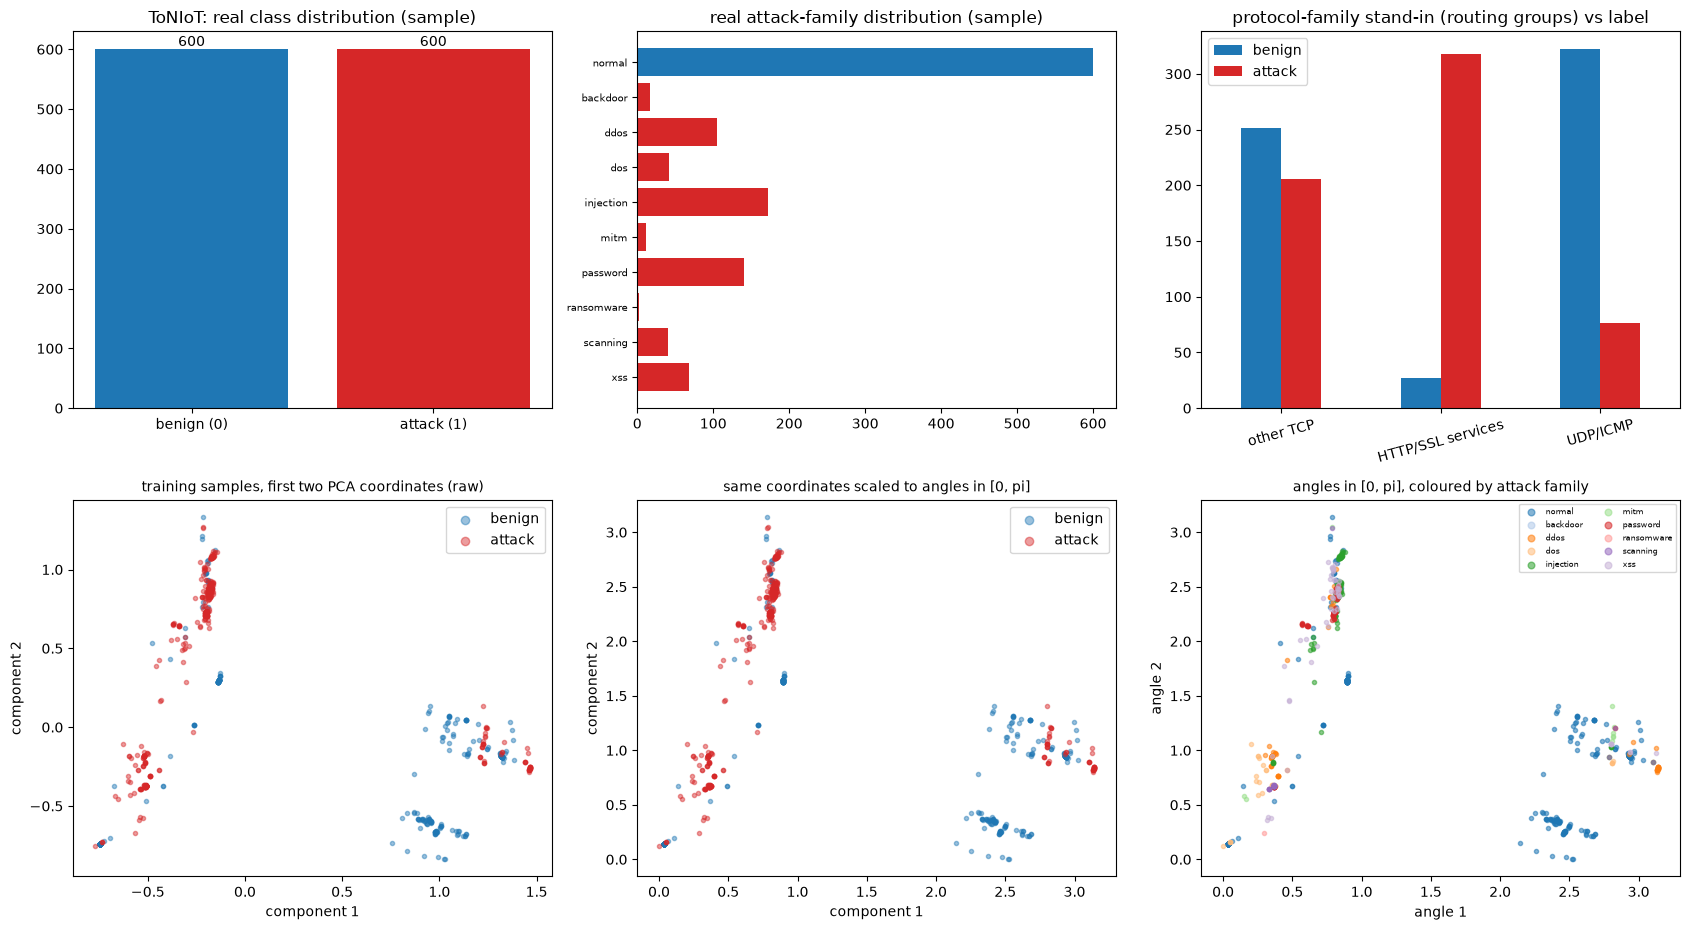

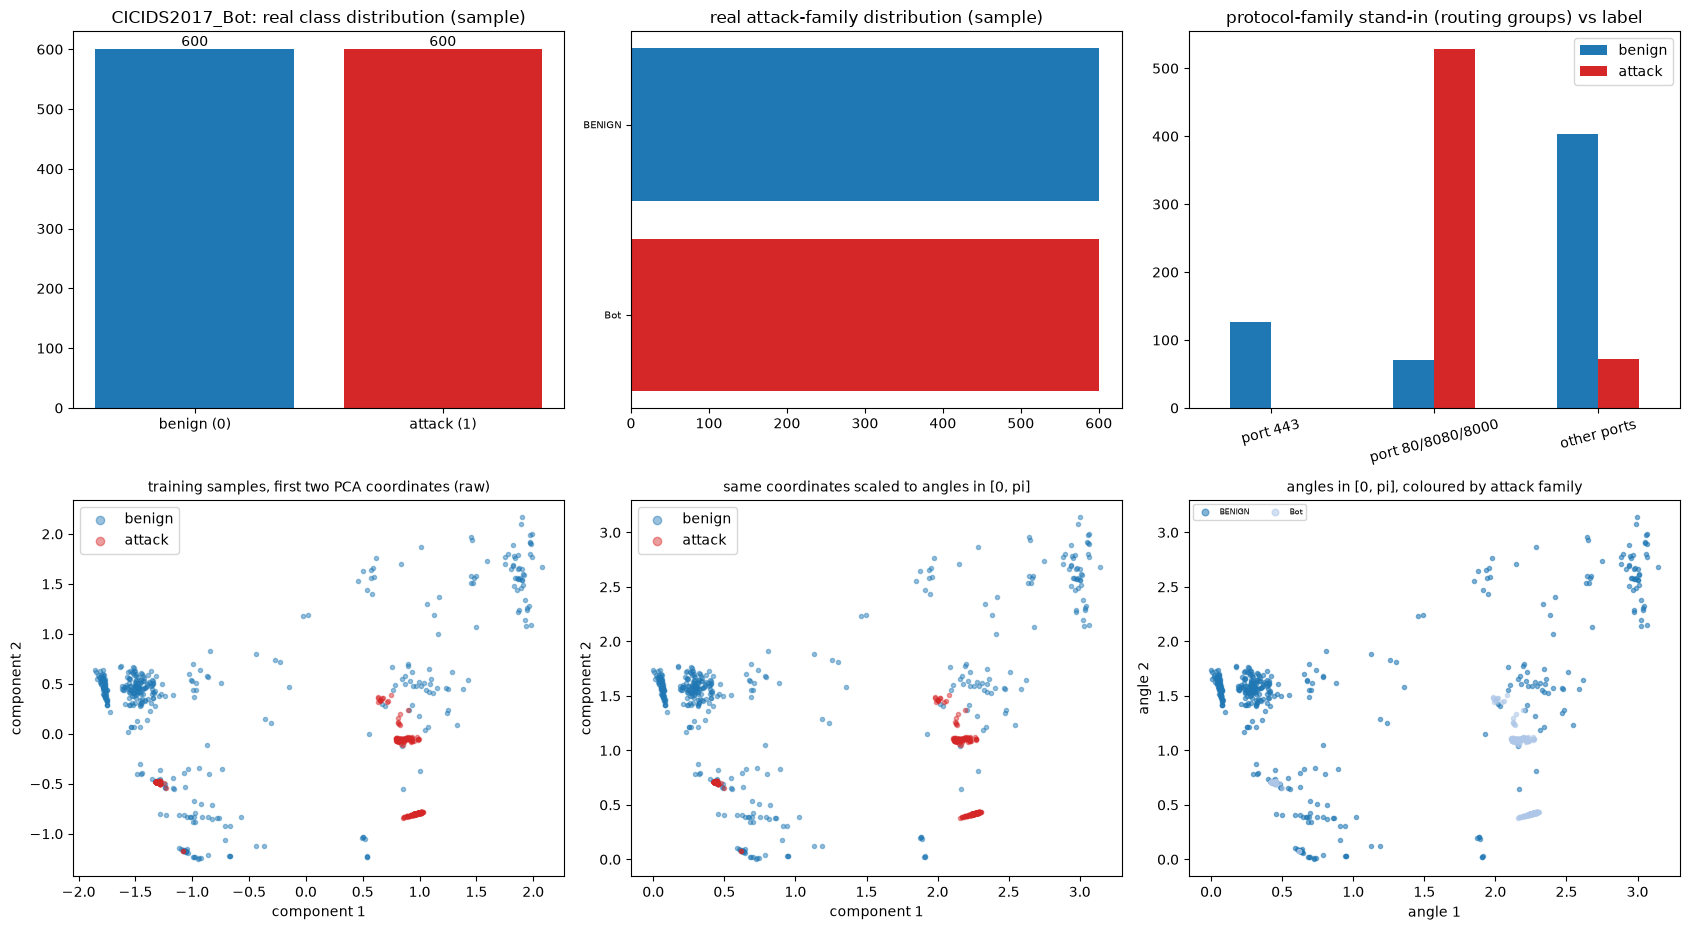

In [7]:
FAM_COLORS = plt.get_cmap("tab20")
for name, ds in SAMPLES.items():
    D = DATA[name]; P = D["prep"]
    xtr = D["train"]["x"].numpy(); ytr = D["train"]["y"].numpy().astype(int); ftr = D["train"]["fam"]
    pc = P.pca_raw(xtr)[:, :2]                                       # raw PCA coordinates (fitted on the training split)
    ang = P.q_angles(xtr)[:, :2]                                     # the same two coordinates scaled to [0, pi]
    fams = sorted(set(ds["family"]))
    fams = [f for f in fams if f.upper() in ("NORMAL", "BENIGN")] + [f for f in fams if f.upper() not in ("NORMAL", "BENIGN")]
    fig, axes = plt.subplots(2, 3, figsize=(17, 9.4))
    # (a) real binary class distribution, (b) real family distribution, (c) protocol-family stand-in vs label
    cnt = pd.Series(ds["y"]).value_counts().sort_index()
    axes[0, 0].bar(["benign (0)", "attack (1)"], cnt.values, color=["tab:blue", "tab:red"]); axes[0, 0].set_title(f"{name}: real class distribution (sample)")
    for i, v in enumerate(cnt.values): axes[0, 0].text(i, v, str(v), ha="center", va="bottom")
    fc = pd.Series(ds["family"]).value_counts().reindex(fams)
    axes[0, 1].barh(range(len(fc)), fc.values, color=[("tab:blue" if f.upper() in ("NORMAL", "BENIGN") else "tab:red") for f in fc.index])
    axes[0, 1].set_yticks(range(len(fc))); axes[0, 1].set_yticklabels(fc.index, fontsize=7); axes[0, 1].invert_yaxis(); axes[0, 1].set_title("real attack-family distribution (sample)")
    gt = pd.crosstab(ds["group"], ds["y"]).reindex(range(3)).fillna(0)
    gt.index = ds["group_names"]; gt.columns = ["benign", "attack"]
    gt.plot.bar(ax=axes[0, 2], color=["tab:blue", "tab:red"], rot=15); axes[0, 2].set_title("protocol-family stand-in (routing groups) vs label")
    # (d,e) scatter by binary ground truth, raw PCA and [0, pi] angles; (f) scatter by attack family
    for ax, xy, ttl in ((axes[1, 0], pc, "training samples, first two PCA coordinates (raw)"), (axes[1, 1], ang, "same coordinates scaled to angles in [0, pi]")):
        for c, col, lab in ((0, "tab:blue", "benign"), (1, "tab:red", "attack")):
            ax.scatter(xy[ytr == c, 0], xy[ytr == c, 1], s=9, alpha=.45, c=col, label=lab)
        ax.set_title(ttl, fontsize=10); ax.legend(markerscale=2); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    for i, f in enumerate(fams):
        m = ftr == f
        axes[1, 2].scatter(ang[m, 0], ang[m, 1], s=9, alpha=.55, color=FAM_COLORS(i % 20), label=f)
    axes[1, 2].set_title("angles in [0, pi], coloured by attack family", fontsize=10); axes[1, 2].legend(fontsize=6, markerscale=1.6, ncol=2); axes[1, 2].set_xlabel("angle 1"); axes[1, 2].set_ylabel("angle 2")
    plt.tight_layout(); plt.show()

## 2. Classical baselines on the same inputs

Random forest and RBF-SVM are trained on exactly the inputs of the PQ-IDPS pathways: the 32 selected, [0,1]-scaled features (what the classical pathway sees) and the 8 PCA angles (what the quantum pathway sees).
They are *undefended* models; their accuracy on clean data tells how hard the substitute datasets are, and their accuracy under the same white-box attack is not defined (they are not differentiable), so they appear only in the clean comparison.

In [8]:
def np_inputs(D, split):
    x = D[split]["x"].numpy(); return x, D["prep"].q_angles(x)

def sk_baselines(D, seed):
    xtr, qtr = np_inputs(D, "train"); xte, qte = np_inputs(D, "test")
    ytr, yte = D["train"]["y"].numpy().astype(int), D["test"]["y"].numpy().astype(int)
    rows = []
    for tag, (A, B) in {f"{D['train']['x'].shape[1]} features": (xtr, xte), f"{N_QUBITS} PCA angles": (qtr, qte)}.items():
        for mname, mk in (("RandomForest", lambda: RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1)),
                          ("SVC (rbf, C=1)", lambda: SVC(kernel="rbf", C=1.0, random_state=seed))):
            t = time.time(); m = mk().fit(A, ytr); pr = m.predict(B); dt = time.time() - t
            rows.append(dict(dataset=D["name"], inputs=tag, model=mname, accuracy=100 * accuracy_score(yte, pr), precision=100 * precision_score(yte, pr, zero_division=0),
                             recall=100 * recall_score(yte, pr), f1=100 * f1_score(yte, pr), seconds=dt))
    return pd.DataFrame(rows)

SK = pd.concat([sk_baselines(DATA[n], SEED) for n in DATASETS], ignore_index=True)
display(SK.round(2))

,dataset,inputs,model,accuracy,precision,recall,f1,seconds
0,ToNIoT,32 features,RandomForest,97.78,97.78,97.78,97.78,1.41
1,ToNIoT,32 features,"SVC (rbf, C=1)",96.11,94.62,97.78,96.17,0.05
2,ToNIoT,8 PCA angles,RandomForest,97.22,97.75,96.67,97.21,1.57
3,ToNIoT,8 PCA angles,"SVC (rbf, C=1)",95.00,93.55,96.67,95.08,0.04
4,CICIDS2017_Bot,32 features,RandomForest,98.89,97.83,100.00,98.90,2.05
5,CICIDS2017_Bot,32 features,"SVC (rbf, C=1)",96.11,92.78,100.00,96.26,0.02
6,CICIDS2017_Bot,8 PCA angles,RandomForest,98.89,98.89,98.89,98.89,1.23
7,CICIDS2017_Bot,8 PCA angles,"SVC (rbf, C=1)",96.67,93.75,100.00,96.77,0.02


## 3. The PQ-IDPS model, rebuilt in PyTorch

The paper and its repository describe the model in three parts, all of which are re-implemented here from scratch (the repository's own `PQIDPS` class fuses embeddings, reads *all* qubits and differs from the paper in several places; where they disagree this notebook follows the **paper** and says so):

1. **Classical pathway (CNN-LSTM).** Three 1-D convolution blocks with kernel sizes 3, 5, 7, max pooling, a bidirectional LSTM and a sigmoid output (paper Sec. V-B). The paper feeds it packet sequences of shape T x D; the substitute datasets are *tabular flow records*, so the sequence axis is the (ordered) feature axis. This is a stand-in: the convolutions then act as learned feature mixers, not as temporal filters.
   With the **Lipschitz defence** every convolution and the output layer carries spectral normalisation (weights divided by their largest singular value), the logit is multiplied by the fixed constant K = 5 (the paper's target Lipschitz constant), and a gradient penalty `lambda * max(0, ||grad_x logit||_2 - K)^2` is added (paper Eq. 22). LSTM weights are not normalised (neither in the paper), so the bound is *encouraged*, not guaranteed, for this pathway; the notebook measures the empirical gradient norm.
2. **Quantum pathway (VQC).** Angle encoding `RY(angle_i)` of `N_QUBITS` features, `L = 6` layers of `RY(theta) RZ(phi)` on every qubit followed by a ring of CNOTs (qubit i controls (i+1) mod n), and the Pauli-Z expectation of the first qubit as the read-out (paper Eqs. 9-11), followed by a trainable affine map and a sigmoid (as in the repository). Gradients are obtained by back-propagation through a differentiable state-vector simulator written in PyTorch (the paper's parameter-shift rule gives the same gradients on a noiseless simulator). Its output is checked against PennyLane's `default.qubit` in section 4.
   The **quantum-noise defence** injects depolarizing (p = 0.05), amplitude-damping (gamma = 0.03) and phase-damping (lambda = 0.04) noise on every qubit after every layer *during training only*. A 12-qubit density matrix is out of reach, so the noise is simulated by **quantum trajectories** (every training pass samples one stochastic Kraus branch per qubit and layer); the average over many trajectories equals the density-matrix channel, which is verified against PennyLane's `default.mixed` in section 4.
3. **Protocol detector and adaptive fusion.** A small MLP outputs the three-way softmax `r` (trained with cross-entropy on the protocol-family stand-in); the pathway weights are `w_c = (r_0 + 0.5 r_1)/sum(r)` and `w_q = (r_2 + 0.5 r_1)/sum(r)` (Eqs. 15-16) and `p_ens = w_c p_c + w_q p_q` (Eq. 14). Training minimises `BCE(p_ens) + BCE(p_c) + BCE(p_q) + lambda_GP * GP + 0.5 CE(detector)` (Algorithm 1 trains the pathways and the ensemble together; the exact weighting of the terms is not given, so it is a CHOICE).
   **Randomized smoothing** adds Gaussian noise `N(0, sigma^2 I)` to the input during training and replaces the prediction by a majority vote over noisy copies at test time (Algorithm 2); the certified radius is `R = sigma/2 (Phi^-1(pA) - Phi^-1(pB))` with `pB = 1 - pA` and `pA` a Clopper-Pearson lower bound.

In [9]:
# ---------------------------------------------------------------- quantum pathway: differentiable state-vector simulator (angle encoding + L x [RY RZ + CNOT ring])
def cnot_ring_perm(n):
    """Basis-state permutation of CNOT(0,1), CNOT(1,2), ..., CNOT(n-1,0) applied in this order (qubit 0 = most significant bit, PennyLane convention)."""
    idx = np.arange(2**n)
    bits = ((idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1)
    b = bits.copy()
    for i in range(n):
        b[:, (i + 1) % n] ^= b[:, i]
    new_idx = (b * (1 << (n - 1 - np.arange(n)))[None, :]).sum(1)
    inv = np.empty_like(new_idx); inv[new_idx] = idx          # state'[new_idx[k]] = state[k]
    return torch.as_tensor(inv, dtype=torch.long)

def kron_chain(Ms):
    out = Ms[0]
    for Mx in Ms[1:]:
        d1, d2 = out.shape[-1], Mx.shape[-1]
        out = (out[..., :, None, :, None] * Mx[..., None, :, None, :]).reshape(*out.shape[:-2], d1 * d2, d1 * d2)
    return out

def rot_matrix(th, ph):
    """RZ(ph) @ RY(th) for tensors of angles -> (..., 2, 2) complex."""
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    em, ep = torch.exp(-0.5j * ph), torch.exp(0.5j * ph)
    return torch.stack([torch.stack([em * c, -em * s], -1), torch.stack([ep * s, ep * c], -1)], -2)

PAULI = {"I": torch.eye(2, dtype=torch.complex64), "X": torch.tensor([[0, 1], [1, 0]], dtype=torch.complex64),
         "Y": torch.tensor([[0, -1j], [1j, 0]], dtype=torch.complex64), "Z": torch.tensor([[1, 0], [0, -1]], dtype=torch.complex64)}

def apply_1q(psi, Mx, q, n):
    """Apply a single-qubit gate (2x2, or one 2x2 per sample) on qubit q of a batch of complex state vectors (B, 2^n)."""
    B = psi.shape[0]
    v = psi.reshape(B, 2**q, 2, 2**(n - q - 1))
    out = torch.einsum('ab,pxbz->pxaz', Mx, v) if Mx.dim() == 2 else torch.einsum('pab,pxbz->pxaz', Mx, v)
    return out.reshape(B, -1)

class VQCSim(nn.Module):
    """Quantum pathway: n qubits, L layers. forward(angles) -> logit; angles in [0, pi] shape (B, n)."""
    def __init__(self, n=N_QUBITS, L=N_LAYERS, p_dep=P_DEPOL, gamma=GAMMA_AMP, lam=LAMBDA_PHASE):
        super().__init__()
        self.n, self.L, self.na = n, L, n // 2
        self.theta = nn.Parameter(torch.rand(L, n, 2) * 2 * math.pi)     # paper Algorithm 1: theta_q ~ Uniform[0, 2 pi]
        self.post = nn.Linear(1, 1)                                       # affine map of <Z_0> in [-1, 1] before the sigmoid (as in the repository)
        with torch.no_grad(): self.post.weight.fill_(4.0); self.post.bias.zero_()   # CHOICE: starts as a steep read-out (sign is learned through theta)
        self.register_buffer("inv", cnot_ring_perm(n))
        self.p_dep, self.gamma, self.lam = p_dep, gamma, lam
        self.p_flip = (1 - math.sqrt(1 - lam)) / 2                         # phase damping == phase-flip channel with this probability
    def _encode(self, ang):
        a = torch.stack([torch.cos(ang / 2), torch.sin(ang / 2)], -1)
        B = ang.shape[0]
        def prod(cols):
            psi = a[:, cols[0], :]
            for q in cols[1:]:
                psi = (psi[:, :, None] * a[:, q, None, :]).reshape(B, -1)
            return psi
        return prod(list(range(self.na))), prod(list(range(self.na, self.n)))
    def _unitary_layer(self, pr, pi_, l, B):
        """One layer RY-RZ on every qubit + CNOT ring. The state is kept as a real and an imaginary part of shape (B, 2^na, 2^nb)."""
        n, A, Bd = self.n, 2**self.na, 2**(self.n - self.na)
        Ms = rot_matrix(self.theta[l, :, 0], self.theta[l, :, 1])
        KA, KB = kron_chain([Ms[q] for q in range(self.na)]), kron_chain([Ms[q] for q in range(self.na, n)])
        pr2, pi2 = pr.permute(1, 0, 2).reshape(A, B * Bd), pi_.permute(1, 0, 2).reshape(A, B * Bd)
        outr, outi = KA.real @ pr2 - KA.imag @ pi2, KA.real @ pi2 + KA.imag @ pr2
        outr = outr.reshape(A, B, Bd).permute(1, 0, 2).reshape(B * A, Bd); outi = outi.reshape(A, B, Bd).permute(1, 0, 2).reshape(B * A, Bd)
        Lr, Li = KB.real.T, KB.imag.T
        nr, ni = outr @ Lr - outi @ Li, outr @ Li + outi @ Lr
        return nr.reshape(B, -1)[:, self.inv].reshape(B, A, Bd), ni.reshape(B, -1)[:, self.inv].reshape(B, A, Bd)
    def _group_apply(self, pr, pi_, G, B):
        """Apply one 2x2 operator per sample and qubit, G: (B, n, 2, 2) complex (all qubits at once, via per-sample Kronecker products of the two halves)."""
        KA = kron_chain([G[:, q] for q in range(self.na)]); KB = kron_chain([G[:, q] for q in range(self.na, self.n)])
        outr, outi = KA.real @ pr - KA.imag @ pi_, KA.real @ pi_ + KA.imag @ pr
        KBt = KB.transpose(1, 2)
        return outr @ KBt.real - outi @ KBt.imag, outr @ KBt.imag + outi @ KBt.real
    def expz0(self, ang):
        """Noiseless <Z_0>: the two halves of the register are updated with real-arithmetic matrix products per layer."""
        B, n = ang.shape[0], self.n
        pa, pb = self._encode(ang)
        pr = pa[:, :, None] * pb[:, None, :]; pi_ = torch.zeros_like(pr)
        for l in range(self.L):
            pr, pi_ = self._unitary_layer(pr, pi_, l, B)
        p = (pr**2 + pi_**2).reshape(B, -1)
        return p[:, : 2**(n - 1)].sum(1) - p[:, 2**(n - 1):].sum(1)
    def expz0_noisy(self, ang):
        """One quantum trajectory per sample: after every layer each qubit suffers depolarizing, amplitude-damping and phase-damping (random Kraus branches).
        Channels on different qubits commute, so all depolarizing branches, then all amplitude-damping branches (sequentially, probabilities from the current state), then all phase flips are applied."""
        B, n = ang.shape[0], self.n
        pa, pb = self._encode(ang)
        pr = pa[:, :, None] * pb[:, None, :]; pi_ = torch.zeros_like(pr)
        eye, X, Y, Z = (PAULI[k] for k in "IXYZ")
        paulis = torch.stack([X, Y, Z])
        sg = math.sqrt(self.gamma); s1g = math.sqrt(1 - self.gamma)
        for l in range(self.L):
            pr, pi_ = self._unitary_layer(pr, pi_, l, B)
            # depolarizing: with probability p apply a uniformly random Pauli
            err = torch.rand(B, n) < self.p_dep
            G = torch.where(err[:, :, None, None], paulis[torch.randint(0, 3, (B, n))], eye.expand(B, n, 2, 2))
            pr, pi_ = self._group_apply(pr, pi_, G, B)
            # amplitude damping: jump (K1) with probability gamma * P(qubit q is |1>), otherwise K0; renormalised at the end of the layer
            fr, fi = pr.reshape(B, -1), pi_.reshape(B, -1)
            for q in range(n):
                vr, vi = fr.reshape(B, 2**q, 2, -1), fi.reshape(B, 2**q, 2, -1)
                pop = (vr**2 + vi**2).sum((1, 3))                                   # (B, 2) un-normalised populations
                jump = (torch.rand(B) < self.gamma * (pop[:, 1] / pop.sum(1)).detach())[:, None, None]
                zero = torch.zeros_like(vr[:, :, 0])
                n0r = torch.where(jump, sg * vr[:, :, 1], vr[:, :, 0]); n0i = torch.where(jump, sg * vi[:, :, 1], vi[:, :, 0])
                n1r = torch.where(jump, zero, s1g * vr[:, :, 1]); n1i = torch.where(jump, zero, s1g * vi[:, :, 1])
                fr = torch.stack([n0r, n1r], 2).reshape(B, -1); fi = torch.stack([n0i, n1i], 2).reshape(B, -1)
            nrm = torch.sqrt((fr**2 + fi**2).sum(1, keepdim=True) + 1e-12)
            pr, pi_ = (fr / nrm).reshape(B, 2**self.na, -1), (fi / nrm).reshape(B, 2**self.na, -1)
            # phase damping == phase flip with probability p_flip
            flip = torch.rand(B, n) < self.p_flip
            G = torch.where(flip[:, :, None, None], Z.expand(B, n, 2, 2), eye.expand(B, n, 2, 2))
            pr, pi_ = self._group_apply(pr, pi_, G, B)
        p = (pr**2 + pi_**2).reshape(B, -1)
        return p[:, : 2**(n - 1)].sum(1) - p[:, 2**(n - 1):].sum(1)
    def forward(self, ang, noisy=False):
        z = self.expz0_noisy(ang) if noisy else self.expz0(ang)
        return self.post(z[:, None])[:, 0]

q_demo = VQCSim()
print("quantum pathway: qubits", q_demo.n, "| layers", q_demo.L, "| rotation parameters", q_demo.theta.numel(), "| output-map parameters", sum(p.numel() for p in q_demo.post.parameters()))

quantum pathway: qubits 8 | layers 6 | rotation parameters 96 | output-map parameters 2


In [10]:
# ---------------------------------------------------------------- classical pathway: CNN-LSTM, optionally Lipschitz-constrained
from torch.nn.utils.parametrizations import spectral_norm as _sn

class CNNLSTM(nn.Module):
    """Three conv blocks (kernel 3, 5, 7) + max-pool + bidirectional LSTM + linear read-out -> logit. spectral=True: spectral normalisation + logit scaled by K_LIP."""
    def __init__(self, spectral, ch=CONV_CHANNELS, hid=LSTM_HIDDEN, layers=LSTM_LAYERS):
        super().__init__()
        SN = (lambda m: _sn(m)) if spectral else (lambda m: m)
        self.c1, self.c2, self.c3 = SN(nn.Conv1d(1, ch[0], 3, padding=1)), SN(nn.Conv1d(ch[0], ch[1], 5, padding=2)), SN(nn.Conv1d(ch[1], ch[2], 7, padding=3))
        self.lstm = nn.LSTM(ch[2], hid, num_layers=layers, batch_first=True, bidirectional=True)
        self.fc = SN(nn.Linear(2 * hid, 1))
        self.scale = K_LIP if spectral else 1.0
    def forward(self, x):
        h = x[:, None, :]
        h = F.max_pool1d(F.relu(self.c3(F.relu(self.c2(F.relu(self.c1(h)))))), 2)       # (B, C, d/2)
        _, (hn, _) = self.lstm(h.transpose(1, 2))
        h = torch.cat([hn[-2], hn[-1]], 1)                                                # last layer, forward and backward states
        return self.scale * self.fc(h)[:, 0]

class Detector(nn.Module):
    """Protocol-type detector (3-way softmax). Spectral-normalised when the Lipschitz defence is on."""
    def __init__(self, d, spectral):
        super().__init__()
        SN = (lambda m: _sn(m)) if spectral else (lambda m: m)
        self.net = nn.Sequential(SN(nn.Linear(d, 32)), nn.ReLU(), SN(nn.Linear(32, 3)))
    def forward(self, x): return self.net(x)

def q_angles_t(x, D):
    """Frozen, differentiable map x in [0,1]^d -> quantum angles in [0, pi]^n (the PCA of the preprocessing)."""
    z = (x - D["q_mean"]) @ D["q_comp"].T
    return torch.clamp((z - D["q_min"]) / D["q_rng"], 0, 1) * math.pi

class PQIDPS(nn.Module):
    def __init__(self, D, use_c=True, use_q=True, fusion="adaptive", lip=True, L=N_LAYERS):
        super().__init__()
        self.D, self.use_c, self.use_q, self.fusion, self.lip = D, use_c, use_q, fusion, lip
        d = D["train"]["x"].shape[1]
        self.cnn = CNNLSTM(spectral=lip) if use_c else None
        self.vqc = VQCSim(L=L) if use_q else None
        self.det = Detector(d, lip) if (use_c and use_q and fusion == "adaptive") else None
        self.qnoise = False                                     # quantum-noise trajectories on/off (training only)
    def forward(self, x):
        out = {}
        if self.use_c: out["lc"] = self.cnn(x); out["pc"] = torch.sigmoid(out["lc"])
        if self.use_q: out["lq"] = self.vqc(q_angles_t(x, self.D), noisy=self.qnoise and self.training); out["pq"] = torch.sigmoid(out["lq"])
        if self.use_c and self.use_q:
            if self.det is not None:
                out["det"] = self.det(x); r = F.softmax(out["det"], -1)
                wc, wq = r[:, 0] + 0.5 * r[:, 1], r[:, 2] + 0.5 * r[:, 1]; s = (wc + wq).clamp_min(1e-8)
                out["wc"], out["wq"] = wc / s, wq / s
            else:
                out["wc"] = out["wq"] = torch.full_like(out["pc"], 0.5)
            out["p"] = out["wc"] * out["pc"] + out["wq"] * out["pq"]
        else:
            out["p"] = out["pc"] if self.use_c else out["pq"]
        return out

m_demo = PQIDPS(DATA[DATASETS[0]])
print("PQ-IDPS (full) trainable parameters:", sum(p.numel() for p in m_demo.parameters()), "| classical pathway:", sum(p.numel() for p in m_demo.cnn.parameters()),
      "| quantum pathway:", sum(p.numel() for p in m_demo.vqc.parameters()), "| detector:", sum(p.numel() for p in m_demo.det.parameters()))

PQ-IDPS (full) trainable parameters: 11990 | classical pathway: 10737 | quantum pathway: 98 | detector: 1155


## Quantum Circuit Architecture

The quantum pathway is a **variational quantum classifier**: angle encoding, six layers of single-qubit `RY`/`RZ` rotations each followed by a ring of CNOTs, and a Pauli-Z read-out on the first qubit (paper Eqs. 9-11, Sec. V-C).
The circuit that is *executed* during training and evaluation is the PyTorch state-vector simulator `VQCSim` above (a plain PennyLane QNode would need one circuit execution per sample; the simulator batches them). To show the real circuit and to prove that the simulator runs exactly
this gate list, the cell below builds the **same gate sequence as a PennyLane QNode**, draws it with `qml.draw_mpl`, prints qubit count / depth / parameter count, and asserts that the QNode and the simulator return the same `<Z_0>` for random inputs.
The next cell validates the quantum-trajectory noise model against PennyLane's exact density-matrix simulator `default.mixed` (3 qubits, 2 layers).

Assumptions where the paper omits circuit details (documented, `# CHOICE:`): (i) the encoding rotation is `RY(angle)` with the angle in [0, pi] (the PCA components scaled as in the reference notebooks), (ii) per layer the order is `RY(theta)` then `RZ(phi)` on every qubit and then the CNOT ring, (iii) the ring is applied as the sequence `CNOT(0,1), CNOT(1,2), ..., CNOT(n-1,0)`, (iv) the read-out is the **first** qubit (paper Eq. 11; the repository sums Z over all qubits), (v) the number of qubits is **8** instead of 12 (CPU budget).

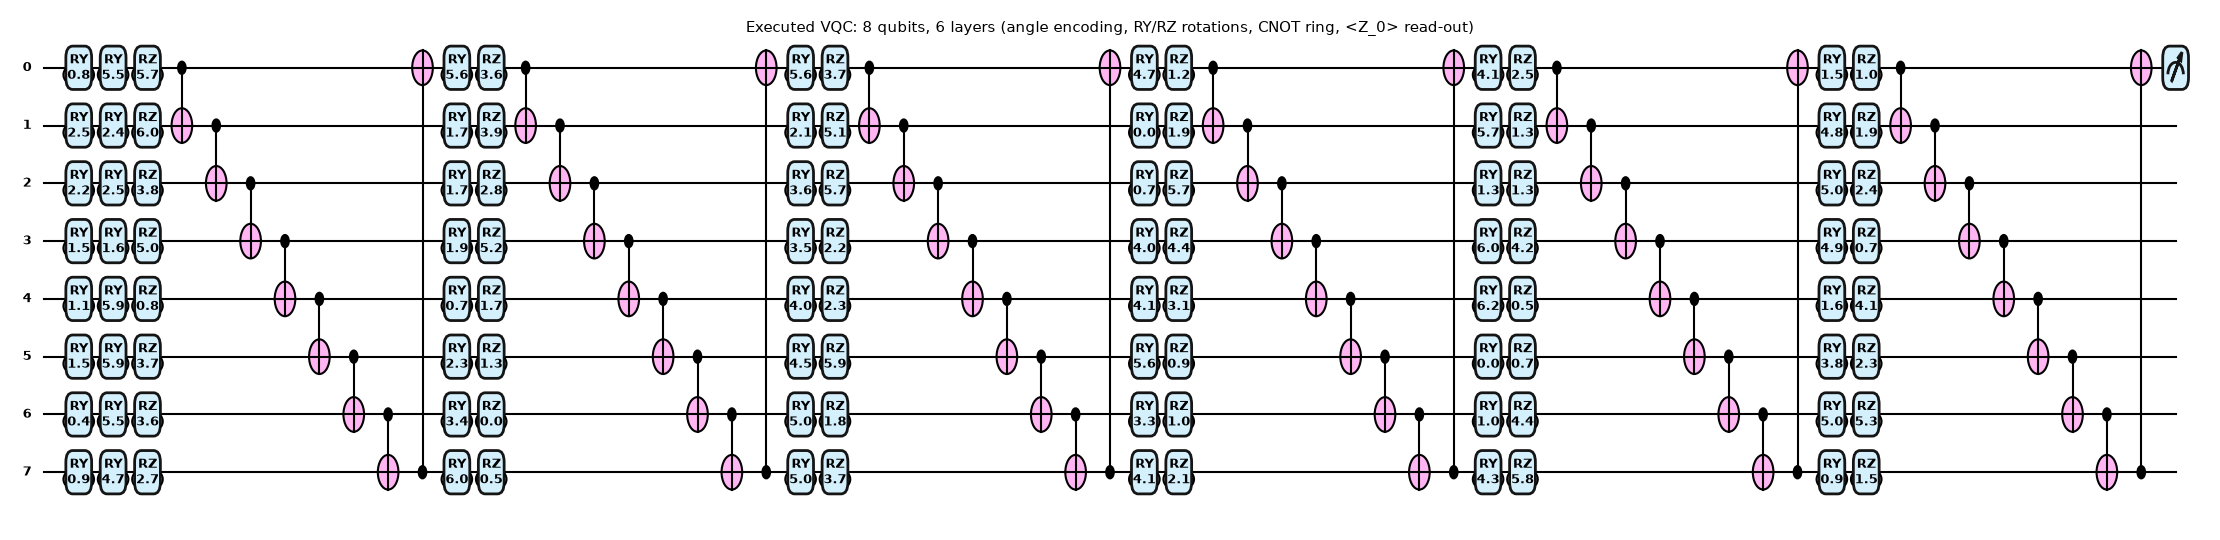

qubits: 8 | circuit depth: 61 | gates: 152 {'RY': 56, 'RZ': 48, 'CNOT': 48} | trainable circuit parameters: 96 (+2 in the classical output map)


simulator == PennyLane QNode: max |difference| = 8.195638656616211e-08


In [11]:
def build_qnode(n, L):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch")
    def circuit(angles, theta):
        for i in range(n):                                   # angle encoding  |psi(x)> = (x) RY(x_i)|0>
            qml.RY(angles[i], wires=i)
        for l in range(L):
            for i in range(n):                               # U_rot(theta_l): RY then RZ on every qubit
                qml.RY(theta[l, i, 0], wires=i)
                qml.RZ(theta[l, i, 1], wires=i)
            for i in range(n):                               # U_ent: ring of CNOTs, qubit i controls (i+1) mod n
                qml.CNOT(wires=[i, (i + 1) % n])
        return qml.expval(qml.PauliZ(0))                     # p(y=1|x) is read from <Z_0>
    return circuit

qnode = build_qnode(N_QUBITS, N_LAYERS)
ex_angles = torch.tensor(DATA[DATASETS[0]]["prep"].q_angles(DATA[DATASETS[0]]["train"]["x"][:1].numpy())[0])
fig, ax = qml.draw_mpl(qnode, decimals=1, style="pennylane", fontsize=9)(ex_angles, q_demo.theta.detach())
fig.set_size_inches(22, 5.2); fig.suptitle(f"Executed VQC: {N_QUBITS} qubits, {N_LAYERS} layers (angle encoding, RY/RZ rotations, CNOT ring, <Z_0> read-out)", fontsize=11); plt.show()

specs = qml.specs(qnode)(ex_angles, q_demo.theta.detach())["resources"]
print(f"qubits: {N_QUBITS} | circuit depth: {specs.depth} | gates: {specs.num_gates} {dict(specs.gate_types)} | trainable circuit parameters: {q_demo.theta.numel()} (+{sum(p.numel() for p in q_demo.post.parameters())} in the classical output map)")

# equivalence: the simulator that is actually trained equals the QNode drawn above
xb = torch.rand(6, N_QUBITS) * math.pi
ref = torch.stack([qnode(xb[b], q_demo.theta.detach()) for b in range(6)]).float()
mine = q_demo.expz0(xb).detach()
assert torch.allclose(ref, mine, atol=1e-5), (ref, mine)
print("simulator == PennyLane QNode: max |difference| =", float((ref - mine).abs().max()))

In [12]:
# validation of the quantum-trajectory noise model against the exact density-matrix result (3 qubits, 2 layers, same channels after every layer)
nq, Lq = 3, 2
vq = VQCSim(nq, Lq); torch.manual_seed(0); vq.theta.data = torch.rand(Lq, nq, 2) * 2 * math.pi
ang = torch.rand(1, nq) * math.pi
devm = qml.device("default.mixed", wires=nq)
@qml.qnode(devm, interface="torch")
def noisy_circuit(angles, theta):
    for i in range(nq): qml.RY(angles[i], wires=i)
    for l in range(Lq):
        for i in range(nq): qml.RY(theta[l, i, 0], wires=i); qml.RZ(theta[l, i, 1], wires=i)
        for i in range(nq): qml.CNOT(wires=[i, (i + 1) % nq])
        for i in range(nq):
            qml.DepolarizingChannel(P_DEPOL, wires=i); qml.AmplitudeDamping(GAMMA_AMP, wires=i); qml.PhaseDamping(LAMBDA_PHASE, wires=i)
    return qml.expval(qml.PauliZ(0))
exact = float(noisy_circuit(ang[0], vq.theta.detach()))
noiseless = float(vq.expz0(ang))
traj = vq.expz0_noisy(ang.repeat(6000, 1)).detach()
print(f"<Z_0>: noiseless {noiseless:+.4f} | exact density matrix (default.mixed) {exact:+.4f} | mean of 6000 trajectories {float(traj.mean()):+.4f} +- {float(traj.std() / math.sqrt(6000)):.4f} (s.e.)")
assert abs(float(traj.mean()) - exact) < 4 * float(traj.std() / math.sqrt(6000)) + 2e-3, "trajectory noise model disagrees with default.mixed"

<Z_0>: noiseless -0.5556 | exact density matrix (default.mixed) -0.3824 | mean of 6000 trajectories -0.3802 +- 0.0053 (s.e.)


## 4. Training, attacks and evaluation machinery

* **Models compared** (names follow the paper's tables): `Classical-NoDefense` (CNN-LSTM without Lipschitz/smoothing/adversarial training), `VQC-Only`, `Hybrid-Static` (hybrid with a fixed 50/50 fusion and all defences), `PQ-IDPS (Ours)` (adaptive fusion + Lipschitz + quantum noise + smoothing), and the single-defence / ablation variants of Tables V and VI.
  `CNN-LSTM (Fine-tuned)` and `PQ-IDS-Baseline` of Table II cannot be built (they need post-quantum fine-tuning data and an unspecified third-party model).
* **Attacks.** The paper's "Grover-optimized quantum attack" is *simulated on a classical computer* (its Limitations section says so): there is no quantum algorithm in the evaluation. We therefore attack with white-box **PGD** (10 steps, no random start) in the paper's own threat model, an **L2 ball of radius eps** (Sec. III-C) inside the [0,1] feature box,
  with eps in {0.1, 0.3, 0.5, 0.7} (Table IV). For comparison: FGSM (one L2 step), PGD in the L-infinity ball, and the repository's "Grover-speed-up" variant (`PGD` with `floor(sqrt(10)) = 3` steps of size 0.01, which is *weaker*, not stronger, than ordinary PGD).
  Models with randomized smoothing are attacked with expectation-over-transformation (the gradient is averaged over noisy copies) and evaluated with their smoothed prediction.
* **Certification.** For every test point, `N_CERT = 100` noisy copies (paper: `N_smooth = 100`), the vote counts, a one-sided Clopper-Pearson lower bound `pA` (alpha = 0.001) and the L2 radius `R = sigma * Phi^-1(pA)` (identical to the paper's Eq. 25 with `pB = 1 - pA`). A point is *certified at eps* when the smoothed prediction is not abstaining and `R >= eps`; *certified accuracy* additionally requires the right label.
* **Scale.** Everything is small enough to run on a CPU: the budgets are in the configuration cell.

In [13]:
EPS_AT = 0.3           # CHOICE: radius of the PGD examples used by the optional adversarial-training row (the repository uses 0.1 in L-infinity)
SUBSET_SEED = 7

CFGS = {   # q/c: pathways present; lip: spectral norm + gradient penalty; qn: quantum noise (training); rs: randomized smoothing; at: PGD adversarial training; fusion: adaptive|fixed
    "Classical-NoDefense":      dict(c=True,  q=False, lip=False, qn=False, rs=False, at=False, fusion="adaptive", level="grid", cert=True),
    "CNN-LSTM (all defences)":  dict(c=True,  q=False, lip=True,  qn=False, rs=True,  at=False, fusion="adaptive", level="grid", cert=True),
    "VQC-Only":                 dict(c=False, q=True,  lip=False, qn=False, rs=False, at=False, fusion="adaptive", level="grid", cert=False),
    "VQC-Only (all defences)":  dict(c=False, q=True,  lip=False, qn=True,  rs=True,  at=False, fusion="adaptive", level="main", cert=False),
    "Hybrid-Static":            dict(c=True,  q=True,  lip=True,  qn=True,  rs=True,  at=False, fusion="fixed",    level="grid", cert=False),
    "PQ-IDPS (Ours)":           dict(c=True,  q=True,  lip=True,  qn=True,  rs=True,  at=False, fusion="adaptive", level="grid", cert=True),
    # defence ablation of Table VI (hybrid with adaptive fusion)
    "Hybrid: no defence":       dict(c=True,  q=True,  lip=False, qn=False, rs=False, at=False, fusion="adaptive", level="main", cert=False),
    "Hybrid: Lipschitz only":   dict(c=True,  q=True,  lip=True,  qn=False, rs=False, at=False, fusion="adaptive", level="main", cert=False),
    "Hybrid: quantum noise only": dict(c=True, q=True, lip=False, qn=True,  rs=False, at=False, fusion="adaptive", level="main", cert=False),
    "Hybrid: smoothing only":   dict(c=True,  q=True,  lip=False, qn=False, rs=True,  at=False, fusion="adaptive", level="main", cert=False),
    "Hybrid: Lipschitz + quantum noise": dict(c=True, q=True, lip=True, qn=True, rs=False, at=False, fusion="adaptive", level="main", cert=False),
    # extra ablations of Table V
    "PQ-IDPS w/o Lipschitz":    dict(c=True,  q=True,  lip=False, qn=True,  rs=True,  at=False, fusion="adaptive", level="main", cert=False),
    "PQ-IDPS w/o quantum noise": dict(c=True, q=True,  lip=True,  qn=False, rs=True,  at=False, fusion="adaptive", level="main", cert=False),
    # beyond the paper: the repository's config also trains on PGD examples (adversarial_ratio 0.5); shown alone, as a reference defence
    "Hybrid: PGD adv. training only": dict(c=True, q=True, lip=False, qn=False, rs=False, at=True, fusion="adaptive", level="main", cert=False),
}
if FAST_MODE:   # keep the class demo under ~10 minutes: drop the rows that only refine Tables V/VI
    for k in ["Hybrid: quantum noise only", "Hybrid: smoothing only", "PQ-IDPS w/o Lipschitz", "PQ-IDPS w/o quantum noise", "Hybrid: PGD adv. training only"]:
        CFGS.pop(k)
print(len(CFGS), "model variants:", list(CFGS))

def build(cfg, D):
    m = PQIDPS(D, use_c=cfg["c"], use_q=cfg["q"], fusion=cfg["fusion"], lip=cfg["lip"], L=cfg.get("L", N_LAYERS)); m.qnoise = cfg["qn"]; return m

def bce(p, y): return F.binary_cross_entropy(p.clamp(1e-6, 1 - 1e-6), y)

def grad_penalty(model, x):
    """Paper Eq. 22: E[max(0, ||grad_x f(x)||_2 - K)^2] for the classical pathway (f = its logit)."""
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(model.cnn(x).sum(), x, create_graph=True)
    return (F.relu(g.flatten(1).norm(dim=1) - K_LIP) ** 2).mean()

def loss_fn(model, cfg, x, y, g):
    out = model(x); L = bce(out["p"], y)
    if model.use_c and model.use_q:
        L = L + bce(out["pc"], y) + bce(out["pq"], y)           # Algorithm 1: pathway losses + ensemble loss
        if "det" in out: L = L + 0.5 * F.cross_entropy(out["det"], g)
    if cfg["lip"] and model.use_c: L = L + LAMBDA_GP * grad_penalty(model, x[:16])
    return L

# ---------------------------------------------------------------- attacks (white box, inside the [0,1] feature box)
def attack_loss(model, xa, y, rs, eot):
    tot = 0.0
    for _ in range(eot if rs else 1):
        xin = xa + SIGMA * torch.randn_like(xa) if rs else xa
        tot = tot + F.binary_cross_entropy(model(xin)["p"].clamp(1e-6, 1 - 1e-6), y, reduction="sum")
    return tot / (eot if rs else 1)

def pgd(model, x, y, eps, norm="l2", steps=PGD_STEPS_EVAL, alpha=None, rs=False, eot=EOT):
    was = model.training; model.eval()
    alpha = alpha if alpha is not None else 2.5 * eps / steps
    xa = x.clone()
    for _ in range(steps):
        xa.requires_grad_(True)
        g, = torch.autograd.grad(attack_loss(model, xa, y, rs, eot), xa)
        xa = xa.detach()
        if norm == "linf":
            xa = xa + alpha * g.sign(); d = (xa - x).clamp(-eps, eps)
        else:
            gn = g.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1)
            xa = xa + alpha * g / gn; d = xa - x
            dn = d.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1)
            d = d * torch.clamp(eps / dn, max=1.0)
        xa = (x + d).clamp(0, 1)
    model.train(was)
    return xa.detach()

def fgsm(model, x, y, eps, rs=False): return pgd(model, x, y, eps, "l2", steps=1, alpha=eps, rs=rs)
def grover_repo(model, x, y, eps, rs=False):      # the repository's "Grover-speed-up" attack: floor(sqrt(10)) = 3 PGD steps of size 0.01 inside the L-inf ball
    return pgd(model, x, y, eps, "linf", steps=int(math.sqrt(10)), alpha=0.01, rs=rs)

ATTACKS = {"pgd_l2": lambda m, x, y, e, rs: pgd(m, x, y, e, "l2", rs=rs), "fgsm_l2": lambda m, x, y, e, rs: fgsm(m, x, y, e, rs),
           "pgd_linf": lambda m, x, y, e, rs: pgd(m, x, y, e, "linf", rs=rs), "grover_repo_linf": lambda m, x, y, e, rs: grover_repo(m, x, y, e, rs)}
LEVELS = {"main": [("pgd_l2", EPS_MAIN), ("fgsm_l2", EPS_MAIN)],
          "grid": [("pgd_l2", e) for e in EPS_GRID] + [("fgsm_l2", EPS_MAIN), ("pgd_linf", 0.1), ("grover_repo_linf", 0.1)]}

14 model variants: ['Classical-NoDefense', 'CNN-LSTM (all defences)', 'VQC-Only', 'VQC-Only (all defences)', 'Hybrid-Static', 'PQ-IDPS (Ours)', 'Hybrid: no defence', 'Hybrid: Lipschitz only', 'Hybrid: quantum noise only', 'Hybrid: smoothing only', 'Hybrid: Lipschitz + quantum noise', 'PQ-IDPS w/o Lipschitz', 'PQ-IDPS w/o quantum noise', 'Hybrid: PGD adv. training only']


In [14]:
# ---------------------------------------------------------------- prediction (smoothed when the model uses randomized smoothing), certification, training
@torch.no_grad()
def predict(model, x, rs, n_smooth=N_SMOOTH, bs=512):
    model.eval(); preds, scores = [], []
    for i in range(0, len(x), bs):
        xb = x[i:i + bs]
        if rs:
            votes, ps = torch.zeros(len(xb)), torch.zeros(len(xb))
            for _ in range(n_smooth):
                p = model(xb + SIGMA * torch.randn_like(xb))["p"]; votes += (p >= 0.5).float(); ps += p
            preds.append((votes / n_smooth >= 0.5).float()); scores.append(ps / n_smooth)
        else:
            p = model(xb)["p"]; preds.append((p >= 0.5).float()); scores.append(p)
    return torch.cat(preds), torch.cat(scores)

def clopper_pearson_lower(k, n, alpha):
    return 0.0 if k == 0 else float(beta.ppf(alpha, k, n - k + 1))

@torch.no_grad()
def certify(model, x, y, sigma=SIGMA, n=N_CERT, alpha=CERT_ALPHA, chunk=8):
    """Randomized-smoothing certificate (Cohen et al.; paper Algorithm 2 / Eq. 25). Returns radius, predicted class, correctness per point."""
    model.eval(); radii, correct = [], []
    for i in range(0, len(x), chunk):
        xb = x[i:i + chunk]; m = len(xb)
        p = model((xb[:, None, :] + sigma * torch.randn(m, n, xb.shape[1])).reshape(m * n, -1))["p"].reshape(m, n)
        v1 = (p >= 0.5).sum(1)
        for j in range(m):
            top = int(v1[j] >= n - v1[j]); nA = int(max(v1[j], n - v1[j]))
            pA = clopper_pearson_lower(nA, n, alpha)
            radii.append(sigma * float(norm.ppf(pA)) if pA > 0.5 else 0.0)
            correct.append(top == int(y[i + j]))
    return np.array(radii), np.array(correct)

def train_model(name, cfg, D, seed, epochs=EPOCHS, verbose=False):
    seed_everything(seed); model = build(cfg, D)
    qp = list(model.vqc.parameters()) if model.use_q else []
    op = [p for n_, p in model.named_parameters() if not n_.startswith("vqc.")]
    opt = torch.optim.AdamW([{"params": op, "lr": LR_CLASSICAL}, {"params": qp, "lr": LR_QUANTUM}], weight_decay=WEIGHT_DECAY)
    tr, va = D["train"], D["val"]; n = len(tr["y"]); best, best_state, bad, hist = 1e9, None, 0, []
    gen = torch.Generator().manual_seed(seed); gv = torch.Generator().manual_seed(1234)
    noise_v = SIGMA * torch.randn(va["x"].shape, generator=gv) if cfg["rs"] else 0.0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(n, generator=gen); tot = 0.0
        for i in range(0, n, BATCH):
            ix = perm[i:i + BATCH]; x, y, g = tr["x"][ix], tr["y"][ix], tr["g"][ix]
            if cfg["at"]:
                h = len(ix) // 2; xa = pgd(model, x[:h], y[:h], EPS_AT, "l2", steps=PGD_STEPS_TRAIN, rs=False); model.train()
                x = torch.cat([xa, x[h:]])
            if cfg["rs"]: x = x + SIGMA * torch.randn_like(x)
            opt.zero_grad(); L = loss_fn(model, cfg, x, y, g); L.backward(); opt.step(); tot += float(L) * len(ix)
        model.eval()
        with torch.no_grad(): lv = float(bce(model(va["x"] + noise_v)["p"], va["y"]))
        hist.append((tot / n, lv))
        if verbose: print(f"    {name} epoch {ep:2d}/{epochs} train loss {tot / n:.3f}  val loss {lv:.3f}")
        if lv < best - 1e-4: best, best_state, bad = lv, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state); model.eval()
    return model, time.time() - t0, hist

def evaluate(name, cfg, model, D, seed):
    te = D["test"]; rs = cfg["rs"]; r = {}
    seed_everything(seed + 1000)
    t = time.time(); pred, score = predict(model, te["x"], rs); r["predict_s"] = time.time() - t
    y = te["y"]; yn = y.numpy().astype(int); pn = pred.numpy().astype(int)
    r.update(acc=100 * accuracy_score(yn, pn), precision=100 * precision_score(yn, pn, zero_division=0), recall=100 * recall_score(yn, pn, zero_division=0),
             f1=100 * f1_score(yn, pn, zero_division=0), auc=100 * roc_auc_score(yn, score.numpy()), cm=confusion_matrix(yn, pn, labels=[0, 1]))
    r["group_acc"] = {int(g): 100 * float((pred[te["g"] == g] == y[te["g"] == g]).float().mean()) for g in range(3) if (te["g"] == g).any()}
    sub = torch.tensor(np.random.default_rng(SUBSET_SEED).permutation(len(y))[:N_ATTACK_EVAL])
    xs, ys = te["x"][sub], y[sub]
    r["clean_sub"] = 100 * float((predict(model, xs, rs)[0] == ys).float().mean())
    r["adv"], r["adv_cm"] = {}, {}
    for atk, eps in LEVELS[cfg["level"]]:
        xa = ATTACKS[atk](model, xs, ys, eps, rs)
        pa = predict(model, xa, rs)[0]
        r["adv"][f"{atk}@{eps}"] = 100 * float((pa == ys).float().mean())
        if atk == "pgd_l2" and eps == EPS_MAIN: r["adv_cm"] = confusion_matrix(ys.numpy().astype(int), pa.numpy().astype(int), labels=[0, 1])
        if atk == "pgd_l2" and eps == EPS_MAIN: r["l2_moved"] = float((xa - xs).flatten(1).norm(dim=1).mean())
    if model.use_c:                                                    # empirical Lipschitz estimate of the classical pathway: mean gradient norm of the logit
        xg = xs[:64].clone().requires_grad_(True); g, = torch.autograd.grad(model.cnn(xg).sum(), xg)
        r["grad_norm"] = float(g.flatten(1).norm(dim=1).mean())
    if cfg["cert"]:
        radii, corr = certify(model, xs[:N_CERT_POINTS], ys[:N_CERT_POINTS])
        r["cert"] = {f"{e}": 100 * float(np.mean(radii >= e)) for e in (0.1, 0.2, 0.3)}
        r["cert_acc"] = {f"{e}": 100 * float(np.mean((radii >= e) & corr)) for e in (0.1, 0.2, 0.3)}
        r["radii"] = radii
    return r

DATA_BY = {(n, SEED): DATA[n] for n in DATASETS}
def get_data(dname, seed):
    if (dname, seed) not in DATA_BY:
        DATA_BY[(dname, seed)] = prepare(SAMPLES_BY[(dname, seed)], seed)
    return DATA_BY[(dname, seed)]
print("ready")

ready


## 5. Training every variant and evaluating it under attack

One loop trains and evaluates every model variant for each dataset and seed. Progress lines show training time and the headline numbers: clean accuracy (smoothed vote for models with randomized smoothing), accuracy under PGD in the L2 ball of radius 0.3 (the paper's eps for Table VI), and, for the models that are certified, the share of test points certified at radius 0.2 (the paper's Fig. 3 operating point).
A quick sanity check comes first: one epoch of the full model, with the loss printed per epoch, to see that the quantum and the classical pathway both learn.

In [15]:
# sanity check: the full model, verbose, on the first dataset
_D = get_data(DATASETS[0], SEED)
_m, _t, _h = train_model("PQ-IDPS (Ours)", CFGS["PQ-IDPS (Ours)"], _D, SEED, epochs=min(EPOCHS, 4), verbose=True)
with torch.no_grad():
    _o = _m(_D["test"]["x"]); _y = _D["test"]["y"]
print(f"after {len(_h)} epochs ({_t:.0f}s): hybrid acc {100*float(((_o['p']>=.5).float()==_y).float().mean()):.1f}% | classical pathway {100*float(((_o['pc']>=.5).float()==_y).float().mean()):.1f}%"
      f" | quantum pathway {100*float(((_o['pq']>=.5).float()==_y).float().mean()):.1f}% | mean weights w_c {float(_o['wc'].mean()):.2f} w_q {float(_o['wq'].mean()):.2f}")

    PQ-IDPS (Ours) epoch  1/4 train loss 2.638  val loss 0.677


    PQ-IDPS (Ours) epoch  2/4 train loss 2.448  val loss 0.639


    PQ-IDPS (Ours) epoch  3/4 train loss 2.312  val loss 0.629


    PQ-IDPS (Ours) epoch  4/4 train loss 2.218  val loss 0.592
after 4 epochs (48s): hybrid acc 77.8% | classical pathway 76.1% | quantum pathway 69.4% | mean weights w_c 0.53 w_q 0.47


In [16]:
def run_with_retry(fn, tries=4):
    """CHOICE: on a shared or small machine an allocation can fail transiently; free memory and try again instead of losing the whole run."""
    for k in range(tries - 1):
        try: return fn()
        except MemoryError: pass
        except RuntimeError as e:
            if "not enough memory" not in str(e): raise
        gc.collect(); time.sleep(30)
    return fn()

RESULTS, MODELS, TRAIN_S = {}, {}, {}
T_RUN = time.time()
for dname in DATASETS:
    for seed in SEEDS:
        D = get_data(dname, seed)
        for name, cfg in CFGS.items():
            t0 = time.time()
            model, ts, hist = run_with_retry(lambda: train_model(name, cfg, D, seed))
            r = run_with_retry(lambda: evaluate(name, cfg, model, D, seed)); r["train_s"] = ts; r["epochs"] = len(hist)
            RESULTS[(dname, name, seed)] = r; TRAIN_S[(dname, name, seed)] = ts
            if seed == SEEDS[0]: MODELS[(dname, name)] = model
            cs = f" | certified@0.2 {r['cert']['0.2']:.0f}%" if "cert" in r else ""
            print(f"[{dname} seed {seed}] {name:34s} train {ts:5.0f}s ({r['epochs']:2d} ep) | clean {r['acc']:5.1f}% | PGD-L2@{EPS_MAIN} {r['adv'][f'pgd_l2@{EPS_MAIN}']:5.1f}%{cs} | total {time.time()-t0:4.0f}s", flush=True)
print(f"all models trained and evaluated in {(time.time()-T_RUN)/60:.1f} min")

[ToNIoT seed 42] Classical-NoDefense                train     7s (15 ep) | clean  96.1% | PGD-L2@0.3  51.7% | certified@0.2 41% | total   10s


[ToNIoT seed 42] CNN-LSTM (all defences)            train    34s (15 ep) | clean  89.4% | PGD-L2@0.3  77.8% | certified@0.2 82% | total   44s


[ToNIoT seed 42] VQC-Only                           train    16s (15 ep) | clean  95.0% | PGD-L2@0.3  86.1% | total   20s


[ToNIoT seed 42] VQC-Only (all defences)            train    69s ( 7 ep) | clean  78.9% | PGD-L2@0.3  56.7% | total   75s


[ToNIoT seed 42] Hybrid-Static                      train   170s (15 ep) | clean  90.6% | PGD-L2@0.3  76.1% | total  196s


...

[CICIDS2017_Bot seed 43] Hybrid: Lipschitz + quantum noise  train   146s (15 ep) | clean  90.0% | PGD-L2@0.3  86.1% | total  147s


[CICIDS2017_Bot seed 43] PQ-IDPS w/o Lipschitz              train   114s (12 ep) | clean  90.0% | PGD-L2@0.3  85.6% | total  121s


[CICIDS2017_Bot seed 43] PQ-IDPS w/o quantum noise          train    40s (15 ep) | clean  94.4% | PGD-L2@0.3  85.6% | total   46s


[CICIDS2017_Bot seed 43] Hybrid: PGD adv. training only     train    50s (15 ep) | clean  96.1% | PGD-L2@0.3  86.7% | total   51s


all models trained and evaluated in 70.0 min


## 6. Clean detection performance (the analogue of the paper's Table III)

Mean +- standard deviation over the seeds (a single seed in `FAST_MODE`; a test set of about 100-250 samples has a binomial standard error of 1-3 accuracy points, so differences of a few points are noise).
Models with randomized smoothing are scored with their smoothed vote. The last columns give the accuracy on each protocol-family stand-in (the paper's classical / hybrid / PQC columns have no counterpart here: these are *not* post-quantum traffic types).
The scikit-learn baselines of section 2 are repeated at the bottom for reference. Confusion matrices use *attack* as the positive class.

In [17]:
def vals(dname, name, getter):
    v = []
    for s in SEEDS:
        r = RESULTS.get((dname, name, s))
        if r is not None:
            try: v.append(getter(r))
            except (KeyError, TypeError): pass
    return np.array(v, dtype=float)
def ms(v, nd=1):
    return "n/a" if len(v) == 0 else (f"{v.mean():.{nd}f}" if len(v) == 1 else f"{v.mean():.{nd}f} +- {v.std():.{nd}f}")
def mean_of(dname, name, getter):
    v = vals(dname, name, getter); return float(v.mean()) if len(v) else float("nan")

rows = []
for dname in DATASETS:
    print(f"{dname}: protocol-family stand-ins (0 classical-like, 1 hybrid-like, 2 PQC-like) = {DATA[dname]['group_names']}")
    for name in CFGS:
        row = {"dataset": dname, "model": name, "accuracy %": ms(vals(dname, name, lambda r: r["acc"])), "precision %": ms(vals(dname, name, lambda r: r["precision"])),
               "recall %": ms(vals(dname, name, lambda r: r["recall"])), "F1 %": ms(vals(dname, name, lambda r: r["f1"])), "AUC %": ms(vals(dname, name, lambda r: r["auc"]))}
        for g in range(3): row[f"acc family {g} %"] = ms(vals(dname, name, lambda r, g=g: r["group_acc"][g]))
        row["train s"] = ms(vals(dname, name, lambda r: r["train_s"]), 0)
        rows.append(row)
TABLE3 = pd.DataFrame(rows)
display(TABLE3)
print("\nscikit-learn baselines on the same split (seed %d):" % SEED); display(SK.round(1))

ToNIoT: protocol-family stand-ins (0 classical-like, 1 hybrid-like, 2 PQC-like) = ['other TCP', 'HTTP/SSL services', 'UDP/ICMP']
CICIDS2017_Bot: protocol-family stand-ins (0 classical-like, 1 hybrid-like, 2 PQC-like) = ['port 443', 'port 80/8080/8000', 'other ports']


,dataset,model,accuracy %,precision %,recall %,F1 %,AUC %,acc family 0 %,acc family 1 %,acc family 2 %,train s
0,ToNIoT,Classical-NoDefense,95.3 +- 0.8,94.1 +- 2.5,96.7 +- 1.1,95.4 +- 0.7,96.6 +- 0.5,96.2 +- 0.6,94.5 +- 1.7,95.1 +- 1.5,7 +- 0
1,ToNIoT,CNN-LSTM (all defences),86.9 +- 2.5,95.8 +- 1.5,77.2 +- 3.9,85.5 +- 3.0,92.1 +- 3.3,79.4 +- 3.2,93.6 +- 2.7,89.2 +- 2.1,37 +- 3
2,ToNIoT,VQC-Only,92.5 +- 2.5,92.8 +- 2.8,92.2 +- 2.2,92.5 +- 2.5,95.7 +- 1.2,97.0 +- 0.1,93.6 +- 2.7,86.8 +- 4.6,16 +- 0
3,ToNIoT,VQC-Only (all defences),76.9 +- 1.9,76.6 +- 4.2,79.4 +- 13.9,77.0 +- 4.6,82.1 +- 0.5,74.2 +- 17.1,92.7 +- 3.6,64.5 +- 16.2,77 +- 8
4,ToNIoT,Hybrid-Static,87.8 +- 2.8,94.1 +- 1.0,80.6 +- 5.0,86.7 +- 3.3,90.8 +- 3.7,83.2 +- 3.8,93.6 +- 2.7,87.6 +- 2.1,167 +- 3
5,ToNIoT,PQ-IDPS (Ours),87.2 +- 2.8,91.9 +- 3.1,81.7 +- 2.8,86.5 +- 2.9,93.1 +- 2.5,84.8 +- 0.7,93.6 +- 2.7,84.3 +- 5.3,141 +- 17
6,ToNIoT,Hybrid: no defence,92.8 +- 2.2,93.3 +- 3.2,92.2 +- 1.1,92.8 +- 2.2,96.0 +- 0.6,97.8 +- 0.7,93.6 +- 2.7,86.8 +- 4.6,20 +- 1
7,ToNIoT,Hybrid: Lipschitz only,92.8 +- 2.2,93.3 +- 2.2,92.2 +- 2.2,92.7 +- 2.2,95.7 +- 1.5,97.0 +- 0.1,93.6 +- 2.7,87.6 +- 3.8,45 +- 2
8,ToNIoT,Hybrid: quantum noise only,95.0 +- 0.6,95.5 +- 1.0,94.4 +- 2.2,95.0 +- 0.6,96.6 +- 0.2,96.2 +- 0.6,94.5 +- 1.7,94.1 +- 2.7,112 +- 12
9,ToNIoT,Hybrid: smoothing only,90.0 +- 3.9,95.0 +- 0.4,84.4 +- 7.8,89.2 +- 4.6,94.0 +- 2.7,88.3 +- 7.3,93.6 +- 2.7,88.4 +- 1.3,20 +- 5



scikit-learn baselines on the same split (seed 42):


,dataset,inputs,model,accuracy,precision,recall,f1,seconds
0,ToNIoT,32 features,RandomForest,97.8,97.8,97.8,97.8,1.4
1,ToNIoT,32 features,"SVC (rbf, C=1)",96.1,94.6,97.8,96.2,0.0
2,ToNIoT,8 PCA angles,RandomForest,97.2,97.8,96.7,97.2,1.6
3,ToNIoT,8 PCA angles,"SVC (rbf, C=1)",95.0,93.5,96.7,95.1,0.0
4,CICIDS2017_Bot,32 features,RandomForest,98.9,97.8,100.0,98.9,2.1
5,CICIDS2017_Bot,32 features,"SVC (rbf, C=1)",96.1,92.8,100.0,96.3,0.0
6,CICIDS2017_Bot,8 PCA angles,RandomForest,98.9,98.9,98.9,98.9,1.2
7,CICIDS2017_Bot,8 PCA angles,"SVC (rbf, C=1)",96.7,93.8,100.0,96.8,0.0


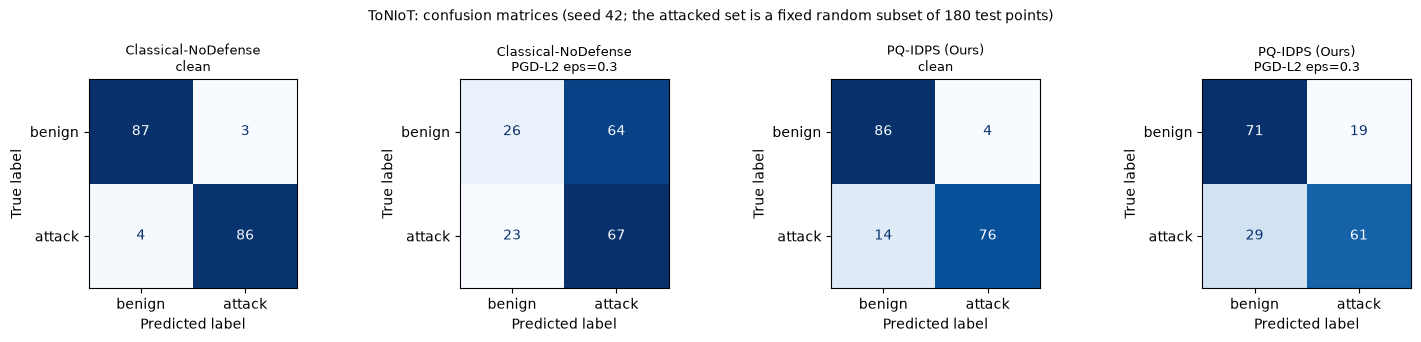

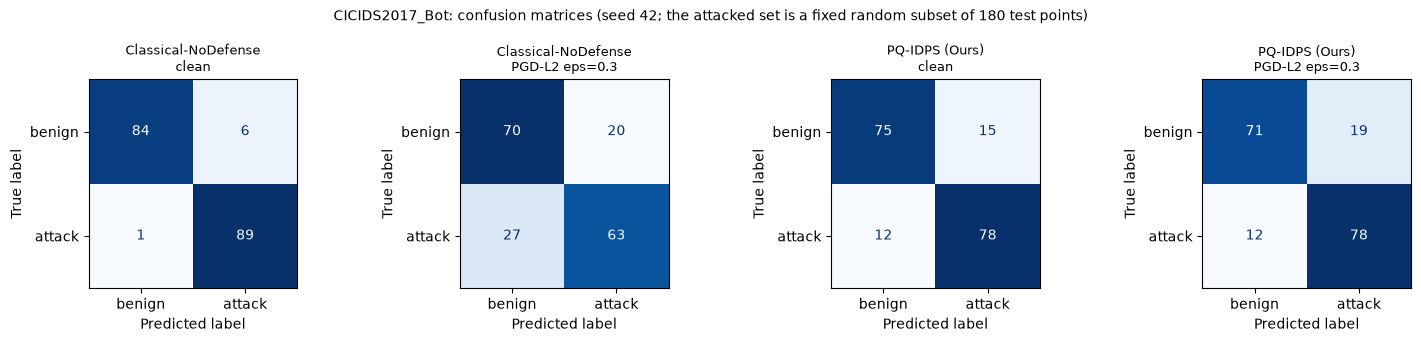

In [18]:
# confusion matrices (attack = positive class), first seed: clean and under PGD-L2 eps = 0.3, for the undefended classical model and for PQ-IDPS
for dname in DATASETS:
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
    for k, (name, key, ttl) in enumerate([("Classical-NoDefense", "cm", "clean"), ("Classical-NoDefense", "adv_cm", f"PGD-L2 eps={EPS_MAIN}"), ("PQ-IDPS (Ours)", "cm", "clean"), ("PQ-IDPS (Ours)", "adv_cm", f"PGD-L2 eps={EPS_MAIN}")]):
        cm = RESULTS[(dname, name, SEEDS[0])][key]
        ConfusionMatrixDisplay(cm, display_labels=["benign", "attack"]).plot(ax=axes[k], colorbar=False, cmap="Blues"); axes[k].set_title(f"{name}\n{ttl}", fontsize=9)
    plt.suptitle(f"{dname}: confusion matrices (seed {SEEDS[0]}; the attacked set is a fixed random subset of {min(N_ATTACK_EVAL, len(DATA[dname]["test"]["y"]))} test points)", fontsize=10); plt.tight_layout(); plt.show()

## 7. Accuracy under attack (the analogue of the paper's Table IV)

Accuracy under white-box PGD in the L2 ball, eps in {0.1, 0.3, 0.5, 0.7}, on a fixed random subset of the test points (all of them in the full mode). Every model is attacked in its own deployed form (smoothed vote + expectation-over-transformation for the smoothed ones).
For orientation, `eps = 0.3` in L2 inside the 32-dimensional [0,1] feature box is a *moderate* perturbation (a change of about 0.05 per feature); eps = 0.7 is large.
The extra columns compare other attacks at eps = 0.3 (FGSM) and the L-infinity attacks at the repository's eps = 0.1 (ordinary PGD vs the repository's 3-step "Grover" variant).

,dataset,model,clean,PGD-L2 eps=0.1,PGD-L2 eps=0.3,PGD-L2 eps=0.5,PGD-L2 eps=0.7,FGSM-L2 0.3,PGD-Linf 0.1,repo 'Grover' Linf 0.1,mean L2 shift
0,ToNIoT,Classical-NoDefense,95.3 +- 0.8,83.9 +- 7.8,44.7 +- 6.9,6.4 +- 6.4,0.3 +- 0.3,73.3 +- 7.2,51.1 +- 23.3,87.2 +- 5.0,0.30 +- 0.00
1,ToNIoT,CNN-LSTM (all defences),85.6 +- 3.9,81.1 +- 6.1,67.8 +- 10.0,33.3 +- 11.1,7.8 +- 6.1,67.8 +- 13.3,66.9 +- 9.2,82.5 +- 5.8,0.30 +- 0.00
2,ToNIoT,VQC-Only,92.5 +- 2.5,91.1 +- 3.3,70.6 +- 15.6,36.9 +- 2.5,8.3 +- 2.2,71.1 +- 15.0,66.7 +- 18.9,91.7 +- 2.8,0.30 +- 0.00
3,ToNIoT,Hybrid-Static,88.3 +- 3.9,85.3 +- 4.2,70.6 +- 5.6,36.9 +- 17.5,5.6 +- 2.8,72.2 +- 6.7,73.6 +- 4.7,86.7 +- 3.9,0.30 +- 0.00
4,ToNIoT,PQ-IDPS (Ours),88.6 +- 3.1,83.3 +- 5.6,71.1 +- 2.2,44.4 +- 17.2,7.5 +- 5.8,73.3 +- 5.6,72.2 +- 1.7,86.4 +- 4.2,0.30 +- 0.00
5,CICIDS2017_Bot,Classical-NoDefense,96.1 +- 0.0,91.1 +- 3.3,65.8 +- 8.1,50.0 +- 1.1,26.1 +- 7.2,70.3 +- 11.4,56.4 +- 0.8,91.4 +- 3.1,0.30 +- 0.00
6,CICIDS2017_Bot,CNN-LSTM (all defences),86.7 +- 0.6,85.0 +- 0.6,83.1 +- 0.8,76.9 +- 1.9,49.2 +- 8.1,83.9 +- 0.0,80.0 +- 1.1,85.6 +- 0.0,0.30 +- 0.00
7,CICIDS2017_Bot,VQC-Only,96.4 +- 0.3,95.6 +- 0.0,83.3 +- 3.3,61.4 +- 10.3,35.6 +- 3.9,84.7 +- 3.1,67.8 +- 8.9,95.6 +- 0.0,0.30 +- 0.00
8,CICIDS2017_Bot,Hybrid-Static,87.2 +- 1.7,86.4 +- 1.4,83.3 +- 1.7,77.2 +- 2.2,48.3 +- 8.3,83.6 +- 1.4,79.2 +- 1.4,86.7 +- 1.7,0.30 +- 0.00
9,CICIDS2017_Bot,PQ-IDPS (Ours),86.4 +- 1.9,85.6 +- 2.2,83.9 +- 1.1,73.6 +- 8.1,51.4 +- 4.7,84.7 +- 1.4,81.1 +- 1.1,85.3 +- 1.9,0.30 +- 0.00


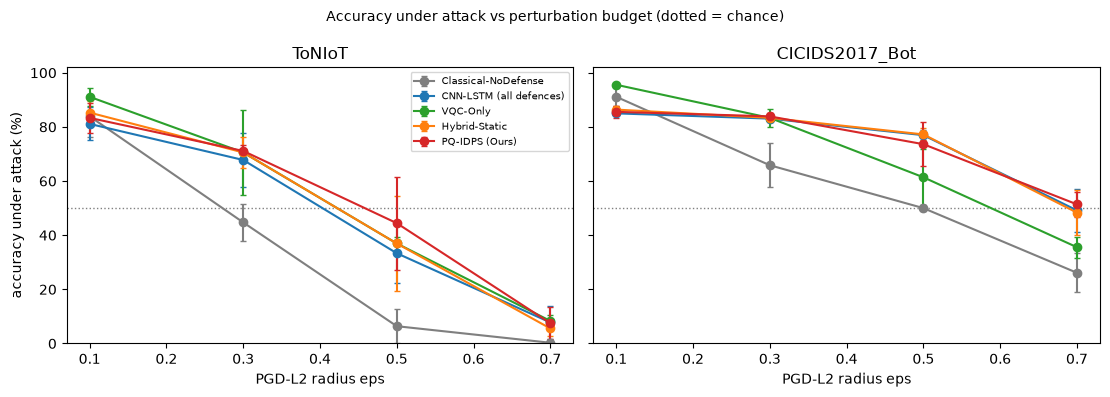

In [19]:
GRID = [n for n, c in CFGS.items() if c["level"] == "grid"]
rows = []
for dname in DATASETS:
    for name in GRID:
        row = {"dataset": dname, "model": name, "clean": ms(vals(dname, name, lambda r: r["clean_sub"]))}
        for e in EPS_GRID: row[f"PGD-L2 eps={e}"] = ms(vals(dname, name, lambda r, e=e: r["adv"][f"pgd_l2@{e}"]))
        row[f"FGSM-L2 {EPS_MAIN}"] = ms(vals(dname, name, lambda r: r["adv"][f"fgsm_l2@{EPS_MAIN}"]))
        row["PGD-Linf 0.1"] = ms(vals(dname, name, lambda r: r["adv"]["pgd_linf@0.1"]))
        row["repo 'Grover' Linf 0.1"] = ms(vals(dname, name, lambda r: r["adv"]["grover_repo_linf@0.1"]))
        row["mean L2 shift"] = ms(vals(dname, name, lambda r: r["l2_moved"]), 2)
        rows.append(row)
TABLE4 = pd.DataFrame(rows); display(TABLE4)

fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.6 * len(DATASETS), 4), sharey=True); axes = np.atleast_1d(axes)
cmap = {"Classical-NoDefense": "tab:gray", "CNN-LSTM (all defences)": "tab:blue", "VQC-Only": "tab:green", "Hybrid-Static": "tab:orange", "PQ-IDPS (Ours)": "tab:red"}
for ax, dname in zip(axes, DATASETS):
    for name in GRID:
        v = np.array([vals(dname, name, lambda r, e=e: r["adv"][f"pgd_l2@{e}"]) for e in EPS_GRID])      # eps x seeds
        ax.errorbar(EPS_GRID, v.mean(1), yerr=v.std(1) if v.shape[1] > 1 else None, marker="o", capsize=2, color=cmap.get(name), label=name)
    ax.axhline(50, color="grey", ls=":", lw=1); ax.set_xlabel("PGD-L2 radius eps"); ax.set_title(dname); ax.set_ylim(0, 102)
axes[0].set_ylabel("accuracy under attack (%)"); axes[0].legend(fontsize=7)
plt.suptitle("Accuracy under attack vs perturbation budget (dotted = chance)", fontsize=10); plt.tight_layout(); plt.show()

## 8. Defence ablation (the analogues of the paper's Tables V and VI)

**Table VI** compares defence strategies at eps = 0.3 (clean and adversarial accuracy of the hybrid model). **Table V** removes one component at a time from the full model; the paper reports *clean hybrid accuracy*, which is shown first, and, because the defences mainly matter under attack, the accuracy under PGD-L2 eps = 0.3 is shown next to it.
In our implementation `w/o protocol detector` has no separate meaning: removing the detector leaves a fixed 50/50 weight, i.e. exactly the `w/o adaptive fusion` row.

In [20]:
def row_for(dname, name, label=None):
    return {"dataset": dname, "configuration": label or name, "clean acc %": ms(vals(dname, name, lambda r: r["acc"])),
            f"adv acc % (PGD-L2 {EPS_MAIN})": ms(vals(dname, name, lambda r: r["adv"][f"pgd_l2@{EPS_MAIN}"])),
            f"FGSM-L2 {EPS_MAIN}": ms(vals(dname, name, lambda r: r["adv"][f"fgsm_l2@{EPS_MAIN}"]))}
T6_ROWS = [("Hybrid: no defence", "No defence"), ("Hybrid: Lipschitz only", "Lipschitz only"), ("Hybrid: quantum noise only", "Quantum noise only"), ("Hybrid: smoothing only", "Randomized smoothing only"),
           ("Hybrid: Lipschitz + quantum noise", "Lipschitz + quantum noise"), ("PQ-IDPS (Ours)", "All defences (PQ-IDPS)"), ("Hybrid: PGD adv. training only", "PGD adversarial training only (beyond the paper)")]
T5_ROWS = [("PQ-IDPS (Ours)", "PQ-IDPS (full)"), ("CNN-LSTM (all defences)", "w/o quantum pathway"), ("VQC-Only (all defences)", "w/o classical pathway"), ("Hybrid-Static", "w/o adaptive fusion (fixed 50-50) = w/o protocol detector"),
           ("PQ-IDPS w/o Lipschitz", "w/o Lipschitz constraints"), ("PQ-IDPS w/o quantum noise", "w/o quantum noise injection"), ("Hybrid: Lipschitz + quantum noise", "w/o randomized smoothing")]
print("TABLE VI analogue: defence strategies, hybrid model"); display(pd.DataFrame([row_for(d, n, l) for d in DATASETS for n, l in T6_ROWS if (d, n, SEEDS[0]) in RESULTS]))
print("TABLE V analogue: ablation"); display(pd.DataFrame([row_for(d, n, l) for d in DATASETS for n, l in T5_ROWS if (d, n, SEEDS[0]) in RESULTS]))
gn_rows = []
for dname in DATASETS:
    for name in ["Classical-NoDefense", "CNN-LSTM (all defences)", "Hybrid: Lipschitz only", "PQ-IDPS (Ours)", "Hybrid-Static"]:
        v = vals(dname, name, lambda r: r["grad_norm"])
        if len(v): gn_rows.append({"dataset": dname, "model": name, "mean ||grad_x logit||_2 of the classical pathway": ms(v, 2)})
print("Empirical Lipschitz estimate (target K = %.0f)" % K_LIP); display(pd.DataFrame(gn_rows))

TABLE VI analogue: defence strategies, hybrid model


,dataset,configuration,clean acc %,adv acc % (PGD-L2 0.3),FGSM-L2 0.3
0,ToNIoT,No defence,92.8 +- 2.2,60.0 +- 14.4,67.2 +- 15.6
1,ToNIoT,Lipschitz only,92.8 +- 2.2,72.5 +- 10.3,73.1 +- 10.3
2,ToNIoT,Quantum noise only,95.0 +- 0.6,63.6 +- 21.4,81.7 +- 5.0
3,ToNIoT,Randomized smoothing only,90.0 +- 3.9,79.7 +- 8.6,83.6 +- 5.8
4,ToNIoT,Lipschitz + quantum noise,93.3 +- 1.1,74.2 +- 10.3,75.3 +- 9.7
5,ToNIoT,All defences (PQ-IDPS),87.2 +- 2.8,71.1 +- 2.2,73.3 +- 5.6
6,ToNIoT,PGD adversarial training only (beyond the paper),92.8 +- 1.7,81.9 +- 10.3,85.8 +- 6.4
7,CICIDS2017_Bot,No defence,96.4 +- 0.3,69.4 +- 9.4,73.1 +- 10.8
8,CICIDS2017_Bot,Lipschitz only,96.4 +- 0.3,84.2 +- 1.9,84.7 +- 1.9
9,CICIDS2017_Bot,Quantum noise only,92.2 +- 0.0,76.7 +- 9.4,87.5 +- 3.1


TABLE V analogue: ablation


,dataset,configuration,clean acc %,adv acc % (PGD-L2 0.3),FGSM-L2 0.3
0,ToNIoT,PQ-IDPS (full),87.2 +- 2.8,71.1 +- 2.2,73.3 +- 5.6
1,ToNIoT,w/o quantum pathway,86.9 +- 2.5,67.8 +- 10.0,67.8 +- 13.3
2,ToNIoT,w/o classical pathway,76.9 +- 1.9,43.3 +- 13.3,53.9 +- 8.3
3,ToNIoT,w/o adaptive fusion (fixed 50-50) = w/o protoc...,87.8 +- 2.8,70.6 +- 5.6,72.2 +- 6.7
4,ToNIoT,w/o Lipschitz constraints,90.0 +- 3.9,76.4 +- 11.4,80.6 +- 10.0
5,ToNIoT,w/o quantum noise injection,90.0 +- 3.3,77.8 +- 9.4,80.3 +- 8.6
6,ToNIoT,w/o randomized smoothing,93.3 +- 1.1,74.2 +- 10.3,75.3 +- 9.7
7,CICIDS2017_Bot,PQ-IDPS (full),86.9 +- 1.9,83.9 +- 1.1,84.7 +- 1.4
8,CICIDS2017_Bot,w/o quantum pathway,86.9 +- 0.8,83.1 +- 0.8,83.9 +- 0.0
9,CICIDS2017_Bot,w/o classical pathway,80.6 +- 6.7,69.2 +- 6.9,71.9 +- 8.1


Empirical Lipschitz estimate (target K = 5)


,dataset,model,mean ||grad_x logit||_2 of the classical pathway
0,ToNIoT,Classical-NoDefense,6.52 +- 1.11
1,ToNIoT,CNN-LSTM (all defences),3.05 +- 0.02
2,ToNIoT,Hybrid: Lipschitz only,3.98 +- 0.45
3,ToNIoT,PQ-IDPS (Ours),3.46 +- 0.15
4,ToNIoT,Hybrid-Static,3.15 +- 0.15
5,CICIDS2017_Bot,Classical-NoDefense,4.45 +- 0.76
6,CICIDS2017_Bot,CNN-LSTM (all defences),2.95 +- 0.16
7,CICIDS2017_Bot,Hybrid: Lipschitz only,3.71 +- 0.39
8,CICIDS2017_Bot,PQ-IDPS (Ours),3.03 +- 0.38
9,CICIDS2017_Bot,Hybrid-Static,2.96 +- 0.01


## 9. Certified robustness by randomized smoothing (the analogue of the paper's Fig. 3)

The paper certifies 82.4 % of test examples at radius R = 0.2 for PQ-IDPS against 67.3 % for the classical baseline. Here the same certificate is computed for the smoothed models (sigma = 0.25, 100 noisy copies, Clopper-Pearson alpha = 0.001).
Note the ceiling of this procedure: with 100 copies the best possible lower bound is `0.001^(1/100) = 0.933`, i.e. a maximum radius of `0.25 * Phi^-1(0.933) = 0.376`. The `Classical-NoDefense` row is smoothed *after* training without noise, which is what a user would get by adding the certificate to an ordinary model.

,dataset,model,certified R>=0.1 %,certified R>=0.2 %,certified R>=0.3 %,certified acc R>=0.1 %,certified acc R>=0.2 %,certified acc R>=0.3 %
0,ToNIoT,Classical-NoDefense,73.3 +- 8.3,46.7 +- 5.8,21.7 +- 5.0,62.9 +- 13.8,42.1 +- 4.6,20.4 +- 6.3
1,ToNIoT,CNN-LSTM (all defences),80.0 +- 5.0,67.5 +- 14.2,29.6 +- 9.6,73.8 +- 5.4,62.5 +- 13.3,27.9 +- 9.6
2,ToNIoT,PQ-IDPS (Ours),81.7 +- 1.7,70.4 +- 4.6,39.2 +- 13.3,75.0 +- 2.5,64.2 +- 5.0,35.4 +- 13.7
3,CICIDS2017_Bot,Classical-NoDefense,67.9 +- 6.2,60.4 +- 0.4,39.2 +- 1.7,65.0 +- 4.2,59.2 +- 0.0,38.8 +- 2.1
4,CICIDS2017_Bot,CNN-LSTM (all defences),94.6 +- 0.4,92.5 +- 0.0,78.8 +- 7.9,85.4 +- 0.4,83.8 +- 0.4,73.3 +- 5.0
5,CICIDS2017_Bot,PQ-IDPS (Ours),95.0 +- 1.7,93.3 +- 1.7,77.9 +- 11.3,85.8 +- 1.7,84.2 +- 1.7,70.0 +- 8.3


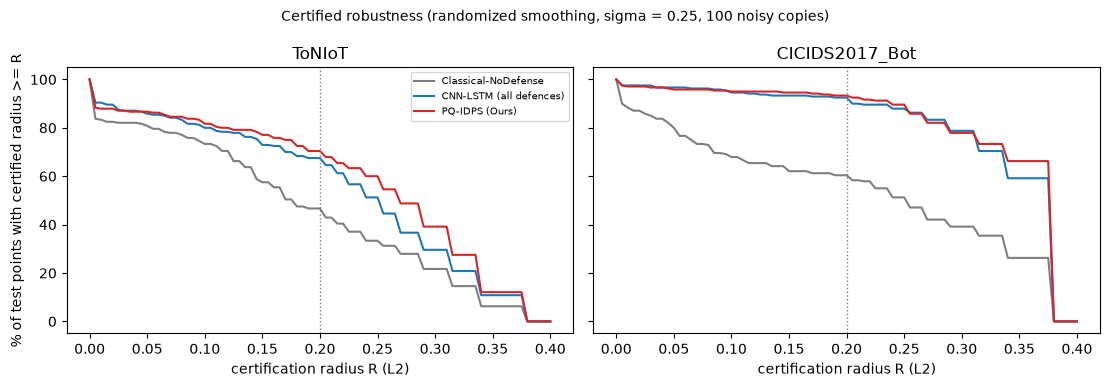

In [21]:
CERT = [n for n, c in CFGS.items() if c["cert"]]
rows = []
for dname in DATASETS:
    for name in CERT:
        row = {"dataset": dname, "model": name}
        for e in ("0.1", "0.2", "0.3"):
            row[f"certified R>={e} %"] = ms(vals(dname, name, lambda r, e=e: r["cert"][e]))
        for e in ("0.1", "0.2", "0.3"):
            row[f"certified acc R>={e} %"] = ms(vals(dname, name, lambda r, e=e: r["cert_acc"][e]))
        rows.append(row)
TABLE_CERT = pd.DataFrame(rows); display(TABLE_CERT)

fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.6 * len(DATASETS), 3.9), sharey=True); axes = np.atleast_1d(axes)
rr = np.linspace(0, 0.4, 81)
for ax, dname in zip(axes, DATASETS):
    for name in CERT:
        curves = [np.array([np.mean(RESULTS[(dname, name, s)]["radii"] >= r_) for r_ in rr]) * 100 for s in SEEDS if (dname, name, s) in RESULTS]
        ax.plot(rr, np.mean(curves, 0), color=cmap.get(name), label=name)
    ax.axvline(0.2, color="grey", ls=":", lw=1); ax.set_xlabel("certification radius R (L2)"); ax.set_title(dname)
axes[0].set_ylabel("% of test points with certified radius >= R"); axes[0].legend(fontsize=7)
plt.suptitle("Certified robustness (randomized smoothing, sigma = %.2f, %d noisy copies)" % (SIGMA, N_CERT), fontsize=10); plt.tight_layout(); plt.show()

## 10. Circuit-depth study and what the router does

*Depth.* The paper varies the number of variational layers from 2 to 10 and reports accuracy rising from 89.3 % to 94.6 % at six layers and then plateauing. The same sweep is run here for the quantum pathway alone (undefended `VQC-Only`), on the first dataset.
*Router.* With the adaptive fusion, the weights given to the two pathways per protocol-family stand-in, and how well the detector recovers the stand-in family from the features.

,layers,rotation parameters,accuracy %
0,2,32,93.9 +- 0.6
1,4,64,92.2 +- 2.8
2,6,96,92.5 +- 2.5
3,8,128,92.2 +- 2.2
4,10,160,92.5 +- 2.5


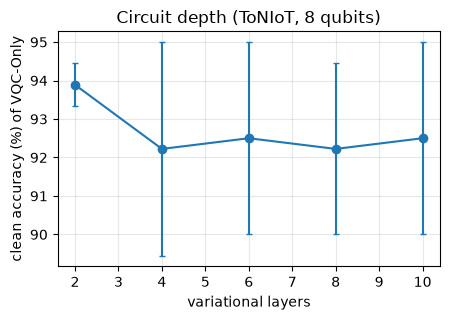

ToNIoT: protocol-family detector accuracy 92.2%


,family (stand-in),share of test set %,mean w_classical,mean w_quantum,acc classical pathway %,acc quantum pathway %
0,other TCP,38.33,0.77,0.23,97.10,85.51
1,HTTP/SSL services,29.44,0.59,0.41,96.23,94.34
2,UDP/ICMP,32.22,0.40,0.60,89.66,75.86


CICIDS2017_Bot: protocol-family detector accuracy 85.6%


,family (stand-in),share of test set %,mean w_classical,mean w_quantum,acc classical pathway %,acc quantum pathway %
0,port 443,13.33,0.63,0.37,62.50,75.00
1,port 80/8080/8000,51.67,0.50,0.50,90.32,96.77
2,other ports,35.00,0.28,0.72,82.54,80.95


Quantum-pathway margins:


,dataset,quantum pathway,mean |<Z_0>| (noiseless inference),mean |logit|,clean acc % (unsmoothed),acc % if the training noise is also applied at inference
0,ToNIoT,VQC-Only,0.275,2.205,95.000,53.0
1,ToNIoT,VQC-Only (all defences),0.141,0.414,79.444,56.0
2,CICIDS2017_Bot,VQC-Only,0.373,2.664,96.667,51.0
3,CICIDS2017_Bot,VQC-Only (all defences),0.116,0.189,77.778,51.0


trained quantum pathway == PennyLane QNode on real test angles (max |diff| = 1.0e-07)


In [22]:
DEPTHS = [2, 6] if FAST_MODE else [2, 4, 6, 8, 10]
drows = []
for L in DEPTHS:
    accs = []
    for seed in SEEDS:
        D = get_data(DATASETS[0], seed)
        cfgL = dict(CFGS["VQC-Only"], L=L)
        m, ts, h = run_with_retry(lambda: train_model(f"VQC L={L}", cfgL, D, seed))
        with torch.no_grad(): p = m(D["test"]["x"])["p"]
        accs.append(100 * float(((p >= 0.5).float() == D["test"]["y"]).float().mean()))
    drows.append({"layers": L, "rotation parameters": N_QUBITS * 2 * L, "accuracy %": ms(np.array(accs)), "_m": float(np.mean(accs)), "_s": float(np.std(accs))})
DEPTH = pd.DataFrame(drows); display(DEPTH.drop(columns=["_m", "_s"]))
plt.figure(figsize=(4.6, 3.3)); plt.errorbar(DEPTH["layers"], DEPTH["_m"], yerr=DEPTH["_s"] if len(SEEDS) > 1 else None, marker="o", capsize=2)
plt.xlabel("variational layers"); plt.ylabel("clean accuracy (%) of VQC-Only"); plt.title(f"Circuit depth ({DATASETS[0]}, {N_QUBITS} qubits)"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

# router diagnostics for the full model (first seed)
for dname in DATASETS:
    mfull = MODELS[(dname, "PQ-IDPS (Ours)")]; te = DATA[dname]["test"]
    with torch.no_grad(): o = mfull(te["x"])
    det_acc = 100 * float((o["det"].argmax(1) == te["g"]).float().mean())
    print(f"{dname}: protocol-family detector accuracy {det_acc:.1f}%")
    display(pd.DataFrame({"family (stand-in)": DATA[dname]["group_names"],
                          "share of test set %": [100 * float((te["g"] == g).float().mean()) for g in range(3)],
                          "mean w_classical": [float(o["wc"][te["g"] == g].mean()) if (te["g"] == g).any() else np.nan for g in range(3)],
                          "mean w_quantum": [float(o["wq"][te["g"] == g].mean()) if (te["g"] == g).any() else np.nan for g in range(3)],
                          "acc classical pathway %": [100 * float(((o["pc"][te["g"] == g] >= .5).float() == te["y"][te["g"] == g]).float().mean()) if (te["g"] == g).any() else np.nan for g in range(3)],
                          "acc quantum pathway %": [100 * float(((o["pq"][te["g"] == g] >= .5).float() == te["y"][te["g"] == g]).float().mean()) if (te["g"] == g).any() else np.nan for g in range(3)]}).round(2))
# why does quantum-noise training hurt under attack? margins of the quantum pathway, plain vs noise-trained (first seed)
rows = []
for dname in DATASETS:
    for name in ["VQC-Only", "VQC-Only (all defences)"]:
        mq_, te_ = MODELS[(dname, name)], DATA[dname]["test"]
        with torch.no_grad():
            z_ = mq_.vqc.expz0(q_angles_t(te_["x"], DATA[dname])); lg_ = mq_.vqc.post(z_[:, None])[:, 0]
            zn_ = torch.stack([mq_.vqc.expz0_noisy(q_angles_t(te_["x"][:100], DATA[dname])) for _ in range(10)]).mean(0)
            acc_n = 100 * float(((mq_.vqc.post(zn_[:, None])[:, 0] >= 0).float() == te_["y"][:100]).float().mean())
        rows.append({"dataset": dname, "quantum pathway": name, "mean |<Z_0>| (noiseless inference)": float(z_.abs().mean()), "mean |logit|": float(lg_.abs().mean()),
                     "clean acc % (unsmoothed)": 100 * float(((lg_ >= 0).float() == te_["y"]).float().mean()), "acc % if the training noise is also applied at inference": acc_n})
print("Quantum-pathway margins:"); display(pd.DataFrame(rows).round(3))
# after training, the simulator still equals the PennyLane QNode (trained parameters, real test angles)
mq = MODELS[(DATASETS[0], "PQ-IDPS (Ours)")].vqc; Dq = DATA[DATASETS[0]]
ang = q_angles_t(Dq["test"]["x"][:6], Dq).detach()
ref = torch.stack([qnode(ang[b], mq.theta.detach()) for b in range(6)]).float()
assert torch.allclose(ref, mq.expz0(ang).detach(), atol=1e-5)
print("trained quantum pathway == PennyLane QNode on real test angles (max |diff| = %.1e)" % float((ref - mq.expz0(ang).detach()).abs().max()))

## 11. Side-by-side with the paper

Every checkable claim is listed with the paper's number, the number measured here and a verdict. A claim is **reproduced** when the notebook's value is within 2 accuracy points of the paper's, **exceeded** / **not reached** otherwise (with the gap), and **cannot be checked** when it depends on data or hardware that is not available.
Because the substitute datasets are intrusion data without post-quantum traffic, a value that matches *by number* is not evidence about the paper's post-quantum story; the last column of the table says what is being compared.

In [23]:
def verdict(paper, ours, tol=2.0):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

def clean(d, n): return mean_of(d, n, lambda r: r["acc"])
def adv(d, n, e=EPS_MAIN): return mean_of(d, n, lambda r: r["adv"][f"pgd_l2@{e}"])
def cert(d, n, e="0.2"): return mean_of(d, n, lambda r: r["cert"][e])

rows = []
def add(claim, paper, ours, what, tol=2.0):
    rows.append({"claim": claim, "paper": paper, "this notebook": (round(ours, 1) if ours == ours else np.nan), "verdict": verdict(paper, ours, tol), "what is compared": what})

for d in DATASETS:
    tag = f"[{d}] "
    add(tag + "PQ-IDPS hybrid-average clean accuracy (Table III)", 93.8, clean(d, "PQ-IDPS (Ours)"), "clean accuracy of the full model on the substitute data (paper: mixed classical/PQC traffic)")
    add(tag + "Classical-NoDefense clean accuracy (Table III, hybrid avg)", 83.7, clean(d, "Classical-NoDefense"), "CNN-LSTM without defences, clean")
    add(tag + "VQC-Only clean accuracy (Table III, hybrid avg)", 88.0, clean(d, "VQC-Only"), "quantum pathway alone, clean")
    add(tag + "Hybrid-Static clean accuracy (Table III)", 91.4, clean(d, "Hybrid-Static"), "hybrid, fixed 50/50 fusion, clean")
    add(tag + "Quantum pathway adds +7.8 points (Table V: 93.8 vs 86.0)", 7.8, clean(d, "PQ-IDPS (Ours)") - clean(d, "CNN-LSTM (all defences)"), "difference PQ-IDPS minus classical-only, clean (points)")
    add(tag + "Adaptive fusion adds +2.4 points over fixed 50/50 (Table V)", 2.4, clean(d, "PQ-IDPS (Ours)") - clean(d, "Hybrid-Static"), "difference of clean accuracies (points)")
    add(tag + "PQ-IDPS accuracy under attack, eps=0.3 (Table IV)", 91.7, adv(d, "PQ-IDPS (Ours)"), "PGD-L2 eps=0.3 on the substitute data")
    add(tag + "Classical-NoDefense under attack, eps=0.3 (Table IV)", 73.2, adv(d, "Classical-NoDefense"), "PGD-L2 eps=0.3")
    add(tag + "Hybrid-Static under attack, eps=0.3 (Table IV)", 85.3, adv(d, "Hybrid-Static"), "PGD-L2 eps=0.3")
    add(tag + "VQC-Only under attack, eps=0.3 (Table IV)", 81.5, adv(d, "VQC-Only"), "PGD-L2 eps=0.3")
    add(tag + "PQ-IDPS under attack, eps=0.7 (Table IV)", 78.9, adv(d, "PQ-IDPS (Ours)", 0.7), "PGD-L2 eps=0.7")
    add(tag + "Classical-NoDefense under attack, eps=0.7 (Table IV)", 44.6, adv(d, "Classical-NoDefense", 0.7), "PGD-L2 eps=0.7")
    add(tag + "Defences gain +18.5 points under attack at eps=0.3 (91.7 vs 73.2)", 18.5, adv(d, "PQ-IDPS (Ours)") - adv(d, "Classical-NoDefense"), "PQ-IDPS minus Classical-NoDefense under PGD-L2 0.3 (points)")
    for n_, pv in (("Hybrid: no defence", 73.2), ("Hybrid: Lipschitz only", 84.5), ("Hybrid: quantum noise only", 83.8), ("Hybrid: smoothing only", 86.7), ("Hybrid: Lipschitz + quantum noise", 88.9)):
        if (d, n_, SEEDS[0]) in RESULTS: add(tag + f"Table VI adversarial accuracy: {n_}", pv, adv(d, n_), "hybrid with that defence, PGD-L2 eps=0.3")
    add(tag + "Certified share at R=0.2, PQ-IDPS (Fig. 3)", 82.4, cert(d, "PQ-IDPS (Ours)"), "share of test points with certified radius >= 0.2")
    add(tag + "Certified share at R=0.2, classical baseline (Fig. 3)", 67.3, cert(d, "Classical-NoDefense"), "same for the undefended CNN-LSTM, smoothed post hoc")
    dp = {int(r_["layers"]): r_["_m"] for _, r_ in DEPTH.iterrows()}
    if d == DATASETS[0] and 2 in dp and 6 in dp:
        add(tag + "Depth: accuracy rises 89.3 -> 94.6 from 2 to 6 layers (+5.3 points)", 5.3, dp[6] - dp[2], "VQC-Only, clean accuracy, 6 layers minus 2 layers (points)")
COMPARE = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 80); display(COMPARE)
print("\nverdict counts:"); print(COMPARE["verdict"].str.split(" ").str[0].value_counts().to_string())

# claims that are directional rather than numeric
for d in DATASETS:
    full_, tr_ = adv(d, "PQ-IDPS (Ours)"), {n_: adv(d, n_) for n_ in ["Hybrid: no defence", "Hybrid: Lipschitz only", "Hybrid: quantum noise only", "Hybrid: smoothing only", "Hybrid: Lipschitz + quantum noise"] if (d, n_, SEEDS[0]) in RESULTS}
    print(f"[{d}] 'all three defences beat every single defence under attack': PQ-IDPS {full_:.1f} vs " + ", ".join(f"{k.replace('Hybrid: ', '')} {v:.1f}" for k, v in tr_.items())
          + f" -> {'holds' if all(full_ >= v for v in tr_.values()) else 'does not hold'} on this run (differences below ~3 points are within noise)")
    print(f"[{d}] 'defended PQ-IDPS keeps more accuracy under attack than the undefended hybrid': {full_ - tr_['Hybrid: no defence']:+.1f} points")

,claim,paper,this notebook,verdict,what is compared
0,[ToNIoT] PQ-IDPS hybrid-average clean accuracy (Table III),93.8,87.2,not reached (-6.6),clean accuracy of the full model on the substitute data (paper: mixed classi...
1,"[ToNIoT] Classical-NoDefense clean accuracy (Table III, hybrid avg)",83.7,95.3,exceeded (+11.6),"CNN-LSTM without defences, clean"
2,"[ToNIoT] VQC-Only clean accuracy (Table III, hybrid avg)",88.0,92.5,exceeded (+4.5),"quantum pathway alone, clean"
3,[ToNIoT] Hybrid-Static clean accuracy (Table III),91.4,87.8,not reached (-3.6),"hybrid, fixed 50/50 fusion, clean"
4,[ToNIoT] Quantum pathway adds +7.8 points (Table V: 93.8 vs 86.0),7.8,0.3,not reached (-7.5),"difference PQ-IDPS minus classical-only, clean (points)"
5,[ToNIoT] Adaptive fusion adds +2.4 points over fixed 50/50 (Table V),2.4,-0.6,not reached (-3.0),difference of clean accuracies (points)
6,"[ToNIoT] PQ-IDPS accuracy under attack, eps=0.3 (Table IV)",91.7,71.1,not reached (-20.6),PGD-L2 eps=0.3 on the substitute data
7,"[ToNIoT] Classical-NoDefense under attack, eps=0.3 (Table IV)",73.2,44.7,not reached (-28.5),PGD-L2 eps=0.3
8,"[ToNIoT] Hybrid-Static under attack, eps=0.3 (Table IV)",85.3,70.6,not reached (-14.7),PGD-L2 eps=0.3
9,"[ToNIoT] VQC-Only under attack, eps=0.3 (Table IV)",81.5,70.6,not reached (-10.9),PGD-L2 eps=0.3



verdict counts:
verdict
not           31
exceeded       6
reproduced     4
[ToNIoT] 'all three defences beat every single defence under attack': PQ-IDPS 71.1 vs no defence 60.0, Lipschitz only 72.5, quantum noise only 63.6, smoothing only 79.7, Lipschitz + quantum noise 74.2 -> does not hold on this run (differences below ~3 points are within noise)
[ToNIoT] 'defended PQ-IDPS keeps more accuracy under attack than the undefended hybrid': +11.1 points
[CICIDS2017_Bot] 'all three defences beat every single defence under attack': PQ-IDPS 83.9 vs no defence 69.4, Lipschitz only 84.2, quantum noise only 76.7, smoothing only 84.4, Lipschitz + quantum noise 85.8 -> does not hold on this run (differences below ~3 points are within noise)
[CICIDS2017_Bot] 'defended PQ-IDPS keeps more accuracy under attack than the undefended hybrid': +14.4 points


**Claims that cannot be checked here** (no post-quantum traffic, no access to the authors' data or hardware):

| Claim | Why it cannot be checked |
|---|---|
| 95.3 % / 93.8 % detection accuracy on *hybrid classical-PQC* traffic, 98.1 % on protocol-mixed traffic | needs CESNET-TLS-22 (institutional agreement), QUIC-PQC and IoT-PQC (unreleased) |
| KL = 2.73 nats and MMD^2 = 0.41 between classical and PQC packet sizes; handshake sizes 3,247 / 5,603 / 7,891 bytes; DTW distances; 94 % timing-based protocol detection | measured on the unreleased captures |
| Table III columns "Classical / PQC" per dataset, cross-dataset transfer (89.3 %, 72.1 %), Fig. 4 (accuracy vs PQC share) | need real classical and post-quantum traffic of the same services |
| 7.8 % quantum contribution **on pure PQC traffic** | the quantum pathway is only tested here on ordinary IoT/TLS-era intrusion data |
| 18 ms inference latency at 10 Gbps on an A100, 18 h training time | hardware-specific; this notebook runs a CPU state-vector simulator |
| Expressibility 0.847 and entanglement scaling `E ~ L^0.73` | no definition of the expressibility measure or of the bipartition is given; not reproducible from the text |
| 6-qubit variant loses 2.3 %, 12-qubit memory of 64 KB | 12 qubits are possible but slow here (`N_QUBITS` in the configuration cell); the 64 KB figure counts one state vector of 2^12 complex numbers |
| `PQ-IDS-Baseline` [25], `CNN-LSTM (Fine-tuned)` | unspecified model / needs PQC fine-tuning data |

**What the saved run says** (the run stored with this notebook: `FAST_MODE = False`, seeds 42 and 43, two datasets; with test sets of 180 points and two seeds, differences of a few points are noise, so read the picture rather than the digits).

* **Clean accuracy.** The undefended models are the best here (CNN-LSTM about 95-96 %, VQC about 92-96 %; random forest and SVM on the same inputs 95-99 %), so the substitute datasets are *easy* and leave little room for a "quantum advantage". The fully defended PQ-IDPS pays about 8-9 points of clean accuracy (mostly the randomized-smoothing vote with sigma = 0.25): about 87 % against the paper's 93.8 % (not reached).
* **Quantum pathway and fusion.** Adding the quantum pathway changes the defended model's accuracy by about 0 points (paper: +7.8); adaptive fusion is no better than fixed 50/50 weights (paper: +2.4). The router does what the equations say (it sends UDP/ICMP-like traffic mostly to the quantum pathway), but on these data that brings no accuracy gain.
* **Depth.** No rise in accuracy from 2 to 6 layers (paper: 89.3 -> 94.6 %); two layers are already enough on 8 PCA inputs.
* **Robustness.** Under PGD in the L2 ball of radius 0.3 the undefended hybrid keeps about 60-69 % and the defended models 71-86 %; each defence alone helps (smoothing and Lipschitz most, quantum noise least, PGD adversarial training about as much as smoothing), which matches the *direction* of the paper's Table VI. The claimed **synergy of all three** (91.7 % versus 86.7 % for the best single defence) is **not** seen: the combination is not better than smoothing alone or than Lipschitz + noise. The gain of the defended model over the undefended classical network (paper: +18.5 points) is reproduced on CIC-IDS2017 and exceeded on TON_IoT, while absolute accuracies at eps = 0.7 are far below the paper's.
* **Certification.** Smoothed models certify much more than the undefended network at R = 0.2 (PQ-IDPS about 70 % / 93 % against about 47 % / 60 %), the direction of Fig. 3; the absolute 82.4 % is exceeded on CIC-IDS2017 (about 93 %) and not reached on TON_IoT (about 70 %).

## 12. Reading the paper critically

*What the numbers above support, and what they do not.* Everything below concerns this notebook's own runs (small models, a few hundred test points, one or two seeds) and the preprint's text; none of it is a verdict on post-quantum intrusion detection in general.

1. **The data cannot be obtained and the public code cannot stand in for it.** The three datasets are unreleased (CESNET-TLS-22 needs an institutional agreement). The repository's loaders fall back to `np.random.randint(0, 2, n)` labels with features drawn independently of the label, so every number the repository can produce on its own is at chance level. The preprint's tables therefore cannot be re-derived by anyone from the released material, and its post-quantum story (distribution shift, per-protocol columns, Fig. 4) is untestable here.
2. **The numbers are not mutually consistent.** The abstract and conclusion say 95.3 % on hybrid classical-PQC traffic; Table III and the text say 93.8 % for the same quantity. The abstract and conclusion attribute the 7.8-point quantum contribution to *pure post-quantum* traffic, while Table V (hybrid traffic) is where it comes from (93.8 - 86.0). The same 91.7 % is called certified accuracy (Contributions) and accuracy under attack (Table IV, VI). The README's key results quote 91.7 % at eps = 0.10 while the paper quotes it at eps = 0.3, and its expected-output block lists per-dataset accuracies that differ from Table III. The Fig. 4 caption and the text give 93.8 % both as the hybrid average and as the floor across all mixing ratios.
3. **The "Grover-optimized attack" is not a quantum attack.** The Limitations section admits it is a classical approximation; the code implements it as ordinary PGD with *fewer* iterations (`floor(sqrt(10)) = 3` steps of size 0.01), which is a weaker attack, not a stronger one: Grover search gives a quadratic speed-up for *unstructured* search, whereas a differentiable model is attacked with gradients. The certification radius "bounded by O(sqrt(N)) Grover advantage" is obtained by simply multiplying sigma by sqrt(2) - that is a modelling choice, not a derived bound.
4. **The defences interact with the threat model.** The text defines an L2 adversary (Sec. III-C), the code attacks in L-infinity, Table IV varies eps from 0.1 to 0.7 without saying in which norm or on which feature scale. Randomized smoothing certifies an L2 radius; "certified accuracy under eps = 0.3 quantum perturbations" and "accuracy under PGD" are different quantities and the preprint mixes them (91.7 % appears as both).
5. **"Quantum-noise injection" is a weak regulariser that the quantum pathway pays for.** In the repository's training script the noise is applied to the *input features* (a 'depolarizing' random mask, a square-root scaling, additive Gaussian noise); the circuit-level `noise_channels` option of the quantum pathway is off by default and never enabled by the trainer. Done properly here (trajectories checked against `default.mixed`), the paper's rates (0.05 / 0.03 / 0.04 per qubit and layer, 8 qubits x 6 layers) contract the read-out strongly: the margin table in section 10 shows a mean |logit| of about 0.2-0.4 for the noise-trained quantum pathway against 2-3 for the plain one, and with the training noise switched on at inference neither reaches better than about 55 % accuracy. As a defence on top of the hybrid its effect under attack is small (single-defence row of Table VI), and the quantum pathway alone with all defences is clearly *less* robust than the plain one.
6. **Lipschitz bounds do not cover the LSTM.** Spectral normalisation is applied to the convolutions and linear layers; the recurrent weights are not constrained, so the claimed bound `L <= K` is not guaranteed. The notebook measures the gradient norm instead (section 8).
7. **Statistics.** The preprint reports five runs, p < 0.001 and confidence intervals for differences of a few points on test sets of unknown size; with the test sizes used here (a few hundred) a binomial standard error is 1-3 points, and the differences between defence variants in the tables above are of that order unless they are large.
8. **A quantum advantage is claimed without a quantum-versus-classical comparison at equal capacity.** The 7.8-point "quantum contribution" is the difference between a CNN-LSTM-only and a hybrid model, i.e. it conflates adding an extra pathway with adding a *quantum* pathway. A classical MLP of the same 100-odd parameters on the same 8 inputs is the control that is missing (exercise 3). Expressibility 0.847 and `E ~ L^0.73` are quoted without definitions.
9. **The theory section is not a proof.** Eq. (18) with an unspecified `epsilon_quantum`, a "confidence refinement lemma" stated in words, and a convergence rate that is a 'continuation' of the authors' earlier work [26] do not establish convergence of the joint training.

*What did reproduce in spirit.* The mechanics work as described: a hybrid CNN-LSTM + VQC model trains end to end, adaptive fusion can be implemented exactly as Eqs. 14-16, spectral normalisation lowers the empirical gradient norm of the classical pathway, and randomized smoothing gives a certified radius. See the verdict table for which of the paper's numbers are matched on the substitute data.

## 13. Exercises

1. **Bigger quantum pathway.** Set `N_QUBITS = 12` in the configuration cell (the paper's value; expect each quantum training step to be several times slower) and compare clean accuracy, robustness and the circuit drawing with 8 qubits.
2. **Noise that does not destroy the signal.** Re-run with `P_DEPOL, GAMMA_AMP, LAMBDA_PHASE = 0.005, 0.003, 0.004`. At what noise level does the noise-trained quantum pathway stop being less robust than the plain one? Plot mean `|<Z_0>|` against the noise level.
3. **The missing classical control.** Replace `VQCSim` by a small MLP with the same number of parameters (about 100) acting on the same 8 angles and repeat the `VQC-Only` and `PQ-IDPS` comparison. Is any "quantum contribution" left?
4. **Attack the router.** The protocol detector is a separate network that an adversary can also fool. Write an attack that maximises the loss with respect to the detector's output only (so that traffic is sent to the weaker pathway) and measure how often it changes the fused decision.
5. **A tighter certificate.** With `N_CERT = 100` the largest certifiable radius is 0.376 (section 9). Raise `N_CERT` to 1000, or change `SIGMA`, and plot certified accuracy against radius for the classical and the hybrid model. How does the clean-accuracy price of a larger `SIGMA` compare with the gain in radius?
6. **Another dataset.** Add a loader for a third public intrusion set (for instance the Edge-IIoTset flow files) to `LOADERS` and define its three protocol families; do the conclusions about the defences change?